# Which tensors two phases can make: the G-closure, certified optimization, and whether one periodic inclusion reaches the bounds

Two isotropic conductors, $\sigma_1<\sigma_2$, are mixed in the plane in prescribed proportions $\theta_1+\theta_2=1$. Which effective tensors $\sigma^*$ can the mixture have? This is the G-closure problem, and in two dimensions it has a complete answer: a Wiener box and two trace inequalities (Lurie and Cherkaev; Murat and Tartar), with the curved boundary attained by sequential laminates of rank two. The second question is the one a designer asks: which of these tensors does one periodic cell reach, a single scale and no limit of ever finer structure, and what does a gradient-based design find when every design is certified instead of trusted?

The interest is that this is relaxation in its simplest setting. Maximizing a linear functional of $\sigma^*$ over two-phase designs has no maximizer in general; the relaxed problem lives on the closed set $G_\theta$, its solutions sit on the boundary, and there the classical optimal structures are laminates, which need an infinite hierarchy of scales to realize an arbitrary boundary point. The isotropic point of the boundary is special: the Hashin-Shtrikman (HS) bound is attained by coated disks, and the periodic literature says that one periodic inclusion with a uniform interior field, an E-inclusion, attains it (P1; Vigdergauz in elasticity; Liu, James and Leo 2007 construct periodic E-inclusions; Liu 2010 shows that a periodic microstructure attains an HS bound if and only if it is a periodic E-inclusion). The opposite hypothesis (P2), suggested by relaxation theory, is that single-scale cells cannot reach HS, and that designs saturate at a positive gap or develop ever finer stripes. The notebook does not argue the question: it computes certified brackets for every design and states what a finite resolution can and cannot decide.

Everything certified here refers to a pixel medium (piecewise constant on an $N\times N$ grid of the unit cell), for which the notebook uses the Q1 bracket of `cellsolver`: a conforming primal bound $U\ge\sigma^*$ and a flux dual bound $L\le\sigma^*$ in the Loewner order, tightened by replicating the pixels $2\times2$ (the bracket at $2N$ lies inside the one at $N$).

## What this notebook shows

- The trace bounds in the form used here equal Grabovsky's form (largest relative difference $1.3\times10^{-15}$ over 2000 random pairs), and the rank-2 laminates lie on them (slack below $2.3\times10^{-15}$ on both curves for 101 weights). Rank-1 laminates give the Wiener means and the isotropic rank-2 laminates give Hashin-Shtrikman, to rounding. At $\theta_1=0.7$ the weak-disk array (Rayleigh multipole solution) lies 9.38% below $\sigma^*_{\rm HS,up}$, against 1.28% at $\theta_1=0.5$; at $\theta_1=0.5$ the pixel disk at $N=64$ has a certified bracket 0.56% of the HS range wide, but the true array's value lies 1.52% of the range above that bracket (the staircase error of the pixel disk), half of the 2.90% headroom.
- The weight of the anisotropic objective is $w=0.73141$, not 0.68: with 0.68 the maximum over the strong-matrix curve moves to $m=0.1921$, and with 0.5 it sits at a laminate corner. The minimum of the objective over $G_\theta$ is 2.85106 (the orientation $\lambda_2+w\lambda_1$, on the lower trace curve at $m=0.4486$); the range used to normalize the gaps of section 5 is therefore 1.9291, not the 1.9209 that the other orientation gives (all section-5 gaps are about 0.4% smaller in relative terms than they would be with that value).
- 300 random cells at $N=32$: none is certified to violate the G-closure, and every one is certified inside, with the trace slacks evaluated at the pessimistic ends of the brackets (smallest slacks 0.0340 and 0.0021, Wiener box 0.0159). The cells lie far from the boundary, so this is a weak test of the inequalities.
- The envelope-theorem gradient $E_p$ equals `jax.grad` through a dense solve to $2.7\times10^{-15}$ over all pixels. A scan of the central-difference step from $10^{-2}$ to $10^{-7}$ is V-shaped (truncation on the left, rounding on the right): the initial step $10^{-6}$ gives a relative error $1.45\times10^{-6}$ on the small entries and the best step, $10^{-4}$, gives $4.5\times10^{-9}$. The gradient of the whole design chain agrees with central differences to $3.7\times10^{-7}$ at $\beta=1,8$ and 32.
- Isotropic maximum, certified brackets at $N=32,64,128$: the best optimizer output has a gap to HS upper (as a share of the HS range) with upper ends of 5.29%, 1.01% and 0.67%, and the certified interval at $N=128$ is $[0.55\%,\,0.67\%]$. Counting the controls, the best design at $N=32$ is the pixel-aligned weak square (2.96%), better than every optimizer output; the optimizer turned its own square start (certified at $[3.21\%,3.46\%]$) into $[19.11\%,21.98\%]$. At $N=128$ the weak square is at $[2.94\%,2.97\%]$ and the weak-disk array at 23.85% (23.89% for the true disk array by Rayleigh). A smooth weak superellipse of exponent $p=8$ at the same pixel count is certified at $[0.54\%,0.66\%]$, so the optimizer's rounded square is, at this resolution, no better than a one-parameter smooth shape. The vector coefficient of variation of the interior field is 0.0366 for the optimized design, against 0.0931 for the square, 0.2460 for the disk and 0.0363 for the smooth superellipse (the discretization floor of a staircase-sampled smooth shape at $N=128$): the order optimized < square < disk is shown at $N=128$ only. The decreasing gap does not separate P1 from P2; what is certified is that, for periodic pixel cells of 128 pixels at weak fraction 0.7002, any single-scale saturation level above 0.67% of the HS range is excluded.
- Anisotropic boundary point: from generic starts the optimizer stops in laminate-like local optima (upper ends of the gap 5% to 20% at $N=64$); from the best weak rectangle it converges to a rounded rectangle with certified gaps (upper ends, as a share of the objective range 1.9291) of 1.22%, 0.95%, 0.75% at $N=32,64,128$, against 1.47%, 1.41%, 1.39% for the raw rectangle and 4.84%, 3.87%, 3.87% for the rank-1 laminate: a factor of about 1.9 and 5.2 at $N=128$, not orders of magnitude. The warm-started designs change by 0.10% and 0.12% of the pixels under refinement, which measures only how far a warm-started optimizer moves and does not test P2. A perturbation test at $N=128$ (2% of the pixels flipped) returns to the design to within 0.05% of the pixels, but at $N=64$ erosion or dilation of the strong phase by one pixel ends in optima with gaps 12.06% and 18.37%. The design is certified inside the $G$-closure with a slack of the upper trace inequality of at least $2.2\times10^{-4}$, on the curve at $m\approx0.20$ and not at the target $m^*=0.25$, with its $\lambda_y$ 0.71% to 0.75% below the curve.

## Conventions

Static, scalar conductivity in the plane; the same problem is the TM static limit (time dependence $e^{-i\omega t}$ drops out; $E$ along $z$ gives $\varepsilon_{zz}$ as the scalar coefficient), and lengths are in units of the period. Phase 1 is weak ($\sigma_1=1$, fraction $\theta_1=0.7$), phase 2 is strong ($\sigma_2=10$, $\theta_2=0.3$). $\lambda_h$ and $\lambda_a$ are the harmonic and arithmetic means. $\sigma^*$ is a symmetric $2\times2$ tensor with eigenvalues $\lambda_1\ge\lambda_2$ when sorted, and $\le$ is the Loewner order. Pixel arrays are `a[i, j]` with $i$ along $x$. A design density $\rho\in[0,1]$ has $\rho=1$ for the strong phase. In section 4 a "gap" is always the certified interval of $(\mathrm{HS_{up}}-\sigma^*_{xx})/(\mathrm{HS_{up}}-\mathrm{HS_{lo}})$, evaluated at the actual pixel fraction of the design (the weak fraction of a binary design is only close to 0.7 and the bounds move with it), reported as a percentage of the HS range; its upper end comes from $L$ and its lower end from $U$. In section 5 the gap is normalized by the range of the objective instead.

In [1]:
import os
for _v in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "VECLIB_MAXIMUM_THREADS"):
    os.environ.setdefault(_v, "4")  # keep the machine usable; must run before numpy is imported
os.environ.setdefault("NPROC", "4")  # size of the XLA CPU thread pool (never 2: see scripts/batch_run.py)
os.environ.setdefault("XLA_FLAGS", "--xla_cpu_multi_thread_eigen=" + ("false" if os.environ["NPROC"] == "1" else "true"))

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from cycler import cycler
import jax
import jax.numpy as jnp

jax.config.update("jax_enable_x64", True)

# Figure style shared by every notebook in notebooks/homogenization (do not edit per notebook).
CAT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]  # series colors, fixed order
INK, INK2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
SEQ = LinearSegmentedColormap.from_list(  # magnitudes: one hue, light to dark
    "seq_blue", ["#eef4fc", "#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"])
DIV = LinearSegmentedColormap.from_list(  # signed quantities: blue, neutral gray, red; use symmetric limits
    "div_blue_red", ["#0d366b", "#256abf", "#6da7ec", "#f0efec", "#ee8f8e", "#d03b3b", "#7d1919"])
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 110, "figure.figsize": (6.4, 4.0),
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.size": 10, "axes.titlesize": 10, "axes.labelsize": 10,
    "legend.fontsize": 9, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "text.color": INK, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": cycler(color=CAT), "lines.linewidth": 1.6, "lines.markersize": 5.5,
    "legend.frameon": False, "image.origin": "lower", "image.interpolation": "nearest", "image.cmap": "seq_blue",
    "figure.constrained_layout.use": True,
})
plt.colormaps.register(SEQ, force=True)
plt.colormaps.register(DIV, force=True)


def check(name, value, tol, target=0.0):
    """Print PASS or FAIL for |value - target| <= tol and assert it, so a rerun catches regressions."""
    err = abs(value - target)
    print(f"{'PASS' if err <= tol else 'FAIL'}  {name}: got {value:.6g}, target {target:.6g}, |diff| {err:.2e} <= {tol:.0e}")
    assert err <= tol, name


def check_in(name, value, lo, hi):
    """Print PASS or FAIL for lo <= value <= hi (a bound, an interval, a sign) and assert it."""
    ok = lo <= value <= hi
    print(f"{'PASS' if ok else 'FAIL'}  {name}: got {value:.6g}, required in [{lo:.6g}, {hi:.6g}]")
    assert ok, name

In [2]:
import sys, pathlib, time
sys.path.insert(0, str(pathlib.Path.cwd()))          # cellsolver.py, bounds.py, rayleigh.py sit next to this notebook
import cellsolver as cs
import bounds as bd
import rayleigh as ry
from scipy.optimize import minimize_scalar

T0 = time.perf_counter()
S1, S2, THETA = 1.0, 10.0, 0.7                       # weak phase, strong phase, weak fraction
HS_LO, HS_UP = bd.hs2d(S1, S2, THETA)
WIENER_H, WIENER_A = bd.wiener(S1, S2, THETA)
print(f"sigma1 = {S1}, sigma2 = {S2}, theta1 = {THETA}")
print(f"Wiener box [{WIENER_H:.5f}, {WIENER_A:.5f}],  Hashin-Shtrikman [{HS_LO:.5f}, {HS_UP:.5f}]")

sigma1 = 1.0, sigma2 = 10.0, theta1 = 0.7
Wiener box [1.36986, 3.70000],  Hashin-Shtrikman [1.65060, 2.71676]


## 1. The G-closure in 2D

**Statement.** Let $\lambda_h=(\theta_1/\sigma_1+\theta_2/\sigma_2)^{-1}$ and $\lambda_a=\theta_1\sigma_1+\theta_2\sigma_2$. The G-closure $G_\theta$ is the set of tensors that are effective conductivities, in the sense of H-convergence, of mixtures of the two phases with local fraction $\theta$; periodic cells are dense in it (standard; from memory). For two isotropic phases in 2D (Lurie and Cherkaev 1984, 1986; Murat and Tartar 1985), $\sigma^*\in G_\theta$ if and only if its eigenvalues $\lambda_1,\lambda_2$ satisfy the Wiener box $\lambda_h\le\lambda_i\le\lambda_a$ and the two trace inequalities

$$\frac1{\lambda_1-\sigma_1}+\frac1{\lambda_2-\sigma_1}\le\frac1{\lambda_h-\sigma_1}+\frac1{\lambda_a-\sigma_1},\qquad \frac1{\sigma_2-\lambda_1}+\frac1{\sigma_2-\lambda_2}\le\frac1{\sigma_2-\lambda_h}+\frac1{\sigma_2-\lambda_a}.$$

The theorem holds for any $\theta$ and, in Grabovsky's form (1993), in any dimension: with $A=\sigma_1I$ the weak and $B=\sigma_2I$ the strong phase, $\operatorname{Tr}A(\sigma^*-A)^{-1}\le\theta_2^{-1}\operatorname{Tr}A(B-A)^{-1}+\theta_1/\theta_2$ and $\operatorname{Tr}B(B-\sigma^*)^{-1}\le\theta_1^{-1}\operatorname{Tr}B(B-A)^{-1}-\theta_2/\theta_1$. The two forms are the same inequalities: with $\Delta=\sigma_2-\sigma_1$ one has $\lambda_a-\sigma_1=\theta_2\Delta$ and $\lambda_h-\sigma_1=\sigma_1\theta_2\Delta/(\theta_1\sigma_2+\theta_2\sigma_1)$, so the right side of the first inequality is $[2\sigma_1+\theta_1\Delta]/(\sigma_1\theta_2\Delta)=\sigma_1^{-1}\big[\theta_2^{-1}\,2\sigma_1/\Delta+\theta_1/\theta_2\big]$, and the second is the same computation at $\sigma_2$. The code below checks this on 2000 random pairs rather than trusting the algebra. The left sides are decreasing (first) and increasing (second) in each eigenvalue, which is what makes certification by Loewner brackets possible in section 2.

**Where the boundary is attained.** The sequential laminate with matrix $\sigma_A$, core $\sigma_B$ of fraction $\theta_B$, layer normals $e_k$ and weights $m_k$ ($\sum m_k=1$) has tensor given by

$$\theta_B\,(\sigma^*-\sigma_AI)^{-1}=(\sigma_B-\sigma_A)^{-1}I+\frac{\theta_A}{\sigma_A}\sum_k m_k\,e_k\otimes e_k$$

(Francfort-Murat and Tartar; from memory, and checked below against the Wiener means, Hashin-Shtrikman and the trace inequalities). Rank one gives the corners $(\lambda_h,\lambda_a)$; rank two with the weak phase as matrix traces the lower trace curve exactly and with the strong phase as matrix the upper one; the isotropic rank-two laminate ($m_1=m_2=\tfrac12$) gives the two HS values, which are the only isotropic points of $G_\theta$ on the boundary. A C4-symmetric cell has isotropic $\sigma^*$ (Schur: a symmetric tensor commuting with a quarter turn is a scalar), so for such cells $\sigma^*\in[\mathrm{HS_{lo}},\mathrm{HS_{up}}]$.

*Checks in this section.* (i) 101 rank-two laminates of each kind lie on their trace curves; (ii) rank one equals Wiener and isotropic rank two equals HS; (iii) the trace-bound form of the module equals Grabovsky's form.

In [3]:
# --- the sequential laminates against the trace bounds
m_grid = np.linspace(0.0, 1.0, 101)
weak_curve = bd.rank2_curve(S1, S2, THETA, m_grid, "weak")        # weak phase is the matrix: lower trace curve
strong_curve = bd.rank2_curve(S1, S2, THETA, m_grid, "strong")    # strong phase is the matrix: upper trace curve
lw_low, lw_up = bd.trace_slacks(weak_curve[:, 0], weak_curve[:, 1], S1, S2, THETA)
ls_low, ls_up = bd.trace_slacks(strong_curve[:, 0], strong_curve[:, 1], S1, S2, THETA)
print("rank-2 laminates, 101 values of the weight m of the x-normal layers")
print(f"  weak matrix  : max |lower slack| = {np.abs(lw_low).max():.2e}   min upper slack = {lw_up.min():+.3e}")
print(f"  strong matrix: max |upper slack| = {np.abs(ls_up).max():.2e}   min lower slack = {ls_low.min():+.3e}")
check("weak-matrix rank-2 laminates lie on the lower trace curve (max |slack| over 101 m)", np.abs(lw_low).max(), 1e-12)
check("strong-matrix rank-2 laminates lie on the upper trace curve (max |slack| over 101 m)", np.abs(ls_up).max(), 1e-12)
check_in("weak-matrix laminates satisfy the other trace inequality (min slack)", lw_up.min(), -1e-12, np.inf)
check_in("strong-matrix laminates satisfy the other trace inequality (min slack)", ls_low.min(), -1e-12, np.inf)

# rank 1 gives the Wiener means, isotropic rank 2 gives Hashin-Shtrikman
rank1 = bd.laminate_seq(S1, S2, 1 - THETA, [0.0], [1.0])           # layer normal x: harmonic mean along x
hs_w = bd.laminate_seq(S1, S2, 1 - THETA, [0.0, np.pi / 2], [0.5, 0.5])
hs_s = bd.laminate_seq(S2, S1, THETA, [0.0, np.pi / 2], [0.5, 0.5])
check("rank-1 laminate, lambda_x = harmonic mean", rank1[0, 0], 1e-14, WIENER_H)
check("rank-1 laminate, lambda_y = arithmetic mean", rank1[1, 1], 1e-14, WIENER_A)
check("isotropic rank-2 laminate, weak matrix = HS lower", hs_w[0, 0], 1e-14, HS_LO)
check("isotropic rank-2 laminate, strong matrix = HS upper", hs_s[0, 0], 1e-14, HS_UP)
check("isotropic rank-2 laminates are isotropic (off-diagonal and difference of diagonals)",
      max(abs(hs_w[0, 1]), abs(hs_w[0, 0] - hs_w[1, 1]), abs(hs_s[0, 1]), abs(hs_s[0, 0] - hs_s[1, 1])), 1e-14)

# the form of the trace bounds used here against the form of Grabovsky (1993)
rng_g = np.random.default_rng(7)
lam_g = rng_g.uniform(WIENER_H + 0.01, WIENER_A - 0.01, size=(2000, 2))
sl_low, sl_up = bd.trace_slacks(lam_g[:, 0], lam_g[:, 1], S1, S2, THETA)
th_A, th_B = THETA, 1 - THETA                                      # A = weak phase (S1), B = strong phase (S2)
lhs_low = S1 * (1 / (lam_g[:, 0] - S1) + 1 / (lam_g[:, 1] - S1))   # Tr(A (C - A)^-1)
rhs_low = (1 / th_B) * (2 * S1 / (S2 - S1)) + th_A / th_B          # (1/theta_B) Tr(A (B - A)^-1) + theta_A / theta_B
lhs_up = S2 * (1 / (S2 - lam_g[:, 0]) + 1 / (S2 - lam_g[:, 1]))    # Tr(B (B - C)^-1)
rhs_up = (1 / th_A) * (2 * S2 / (S2 - S1)) - th_B / th_A           # (1/theta_A) Tr(B (B - A)^-1) - theta_B / theta_A
d_low = np.abs((rhs_low - lhs_low) / S1 - sl_low) / np.maximum(1, np.abs(sl_low))
d_up = np.abs((rhs_up - lhs_up) / S2 - sl_up) / np.maximum(1, np.abs(sl_up))
check("trace_slacks lower = (RHS - LHS) of Grabovsky / sigma1, 2000 random pairs (max relative difference)", d_low.max(), 1e-12)
check("trace_slacks upper = (RHS - LHS) of Grabovsky / sigma2, 2000 random pairs (max relative difference)", d_up.max(), 1e-12)

rank-2 laminates, 101 values of the weight m of the x-normal layers
  weak matrix  : max |lower slack| = 2.22e-15   min upper slack = +0.000e+00
  strong matrix: max |upper slack| = 5.55e-17   min lower slack = +1.110e-15
PASS  weak-matrix rank-2 laminates lie on the lower trace curve (max |slack| over 101 m): got 2.22045e-15, target 0, |diff| 2.22e-15 <= 1e-12
PASS  strong-matrix rank-2 laminates lie on the upper trace curve (max |slack| over 101 m): got 5.55112e-17, target 0, |diff| 5.55e-17 <= 1e-12
PASS  weak-matrix laminates satisfy the other trace inequality (min slack): got 0, required in [-1e-12, inf]
PASS  strong-matrix laminates satisfy the other trace inequality (min slack): got 1.11022e-15, required in [-1e-12, inf]
PASS  rank-1 laminate, lambda_x = harmonic mean: got 1.36986, target 1.36986, |diff| 2.22e-16 <= 1e-14
PASS  rank-1 laminate, lambda_y = arithmetic mean: got 3.7, target 3.7, |diff| 4.44e-16 <= 1e-14
PASS  isotropic rank-2 laminate, weak matrix = HS lower: got 1

The printout above says the laminate formula and the two inequalities are mutually consistent: the equalities hold on the curves to rounding, and the module's form is Grabovsky's. That is consistency, not independent proof of the theorem; section 2 adds a weak second test (random cells, far from the boundary), and sections 4 and 5 the discriminating one (designs near the boundary, certified inside it).

**The choice $\theta_1=0.7$.** The reason for a high weak fraction is the weak-disk array, the obvious single-scale competitor of the HS upper bound, whose conductivity is known exactly by Rayleigh's multipole method (`rayleigh.sigma_eff`, converged in $L$: the table's check compares $L=20$ with $L=40$). At $\theta_1=0.5$ the array is already within 1.28% of $\sigma^*_{\rm HS,up}$ (printed). The cell after the table computes what a certified bracket of the pixel disk at $N=64$ says about that: the bracket is 0.56% of the HS range wide, which resolves the Rayleigh headroom of 2.90% of the range, but the true array's value lies 1.52% of the range above the bracket, because the pixel disk is a staircase and not the disk; the staircase error is half the headroom. At $\theta_1=0.7$ the printed gap is 9.38% of $\sigma^*_{\rm HS,up}$ (23.89% of the range), large enough that certified brackets can see an improvement. At $\theta_1=0.7$ the disks have radius $R=0.47203$, so they nearly touch ($R=0.5$), and the weak phase is the inclusion in a thin strong matrix, which is where the HS upper bound comes from (coated disks with a strong coating).

In [4]:
# --- the weak-disk array and the choice theta1 = 0.7
def rayleigh_disk_weak(f, L=40):
    """sigma* of the square array of weak disks (S1) in the strong host (S2) at weak fraction f: exact multipole solution."""
    return S2 * ry.sigma_eff(f, S1 / S2, L=L)

rows = []
for th in (0.5, 0.7):
    lo, hi = bd.hs2d(S1, S2, th)
    r = rayleigh_disk_weak(th)
    rows.append((th, lo, hi, r, 100 * (hi - r) / hi))
print("weak-disk array (Rayleigh, L = 40) against Hashin-Shtrikman")
print(f"{'theta1':>7s} {'HS lower':>9s} {'HS upper':>9s} {'disks':>9s} {'(HS up - disks)/HS up':>22s}")
for th, lo, hi, r, g in rows:
    print(f"{th:7.2f} {lo:9.5f} {hi:9.5f} {r:9.5f} {g:21.2f}%")
check("Rayleigh weak-disk array at theta = 0.7: L = 20 against L = 40", abs(rayleigh_disk_weak(0.7, 20) - rayleigh_disk_weak(0.7, 40)), 1e-10)
print(f"disk radius at theta = 0.7: R = {np.sqrt(THETA / np.pi):.5f} (touching at R = 0.5)")

# what a certified bracket of the pixel disk at N = 64 says at theta = 0.5 (the 2x2-replicated bracket, as in section 4)
R5 = np.sqrt(0.5 / np.pi)
a5 = cs.disk_pixels(64, R5, S1, S2)
L5, U5 = cs.q1_bracket(np.kron(a5, np.ones((2, 2))))
th5 = np.mean(a5 == S1)
lo5, hi5 = bd.hs2d(S1, S2, th5)
ray5 = rayleigh_disk_weak(th5)
print(f"theta = 0.5, pixel disk at N = 64 (weak fraction {th5:.4f}): certified bracket [{L5[0,0]:.5f}, {U5[0,0]:.5f}] at 2N = 128, width {100*(U5[0,0]-L5[0,0])/(hi5-lo5):.2f}% of the HS range; "
      f"HS upper {hi5:.5f}; Rayleigh value of the true disk array {ray5:.5f} ({100*(hi5-ray5)/(hi5-lo5):.2f}% of the HS range below HS upper), "
      f"{100*(ray5-U5[0,0])/(hi5-lo5):.2f}% of the range above the pixel disk's certified upper end")

weak-disk array (Rayleigh, L = 40) against Hashin-Shtrikman
 theta1  HS lower  HS upper     disks  (HS up - disks)/HS up
   0.50   2.38462   4.19355   4.13999                  1.28%
   0.70   1.65060   2.71676   2.46202                  9.38%
PASS  Rayleigh weak-disk array at theta = 0.7: L = 20 against L = 40: got 3.10862e-14, target 0, |diff| 3.11e-14 <= 1e-10
disk radius at theta = 0.7: R = 0.47203 (touching at R = 0.5)
theta = 0.5, pixel disk at N = 64 (weak fraction 0.4980): certified bracket [4.11939, 4.12949] at 2N = 128, width 0.56% of the HS range; HS upper 4.20966; Rayleigh value of the true disk array 4.15703 (2.90% of the HS range below HS upper), 1.52% of the range above the pixel disk's certified upper end


**The objective of section 5.** To test a boundary point other than the isotropic one, take the point of the upper trace curve at weight $m^*=0.25$ of the strong-matrix rank-two family, $\lambda=(3.24397,\,2.10031)$ (printed). The linear objective $J=\sigma^*_{xx}+w\,\sigma^*_{yy}$ has this point as its unique maximizer over $G_\theta$ when $w$ is the slope that makes the objective's level line tangent to the curve. On $1/(\sigma_2-\lambda_1)+1/(\sigma_2-\lambda_2)=\text{const}$ one has $d\lambda_2/d\lambda_1=-\big((\sigma_2-\lambda_2)/(\sigma_2-\lambda_1)\big)^2$, so $w=\big((\sigma_2-\lambda_1)/(\sigma_2-\lambda_2)\big)^2$. The sorted-eigenvalue region is convex (the left side of the second inequality is convex in $(\lambda_1,\lambda_2)$), and for $w\le1$ and any symmetric $\sigma^*$, $\operatorname{Tr}(\mathrm{diag}(1,w)\,\sigma^*)\le\lambda_1+w\lambda_2$ (a rearrangement inequality), so the maximum over all of $G_\theta$ is the maximum over sorted eigenvalue pairs and is the curve maximum. The same inequality gives the minimum: for $w\le1$, $\operatorname{Tr}(\mathrm{diag}(1,w)\,\sigma^*)\ge\lambda_2+w\lambda_1$ (the larger weight goes to the smaller eigenvalue), so the minimum over $G_\theta$ is the minimum of $\lambda_2+w\lambda_1$ over the sorted region; the scan below locates it on the lower trace curve. A natural guess for this target, $w=0.68$, is wrong. The scan below computes the argmax for $w=0.5$, $0.68$ and the exact weight, and the grid scan over the whole region confirms the curve maximum and locates the minimum.

The closed form `rank2_strong` below is the formula above for diagonal tensors, vectorized; it is checked against `bounds.rank2_curve` before it is used for $J_{\max}$ at the (slightly different) fractions of the pixel designs.

In [5]:
# --- the support line: the weight of the anisotropic objective, computed
m_star = 0.25
lam_star = bd.rank2_curve(S1, S2, THETA, [m_star], "strong")[0]
w_exact = ((S2 - lam_star[0]) / (S2 - lam_star[1])) ** 2           # from d lambda_y / d lambda_x on 1/(s2-l1) + 1/(s2-l2) = const
eps_m = 1e-6
pp, pm = bd.rank2_curve(S1, S2, THETA, [m_star + eps_m], "strong")[0], bd.rank2_curve(S1, S2, THETA, [m_star - eps_m], "strong")[0]
slope = (pp[1] - pm[1]) / (pp[0] - pm[0])
w_fd = -1.0 / slope
print(f"target point of the upper trace curve at m* = {m_star}: lambda = ({lam_star[0]:.5f}, {lam_star[1]:.5f})")
print(f"slope d lambda_y / d lambda_x = {slope:.5f};   w = -1/slope = {w_fd:.5f} (finite difference), {w_exact:.5f} (from the curve equation)")
check("w from the curve equation against the finite-difference slope", w_exact, 1e-6, w_fd)
W_OBJ = w_exact                                                     # objective weight used in section 5


def rank2_strong(theta, m):
    """Closed form of the strong-matrix rank-2 curve (lambda_x, lambda_y) for an array of weights m: theta inv(A - s2 I) = (s1 - s2)^-1 I + ((1-theta)/s2) sum m_k e_k e_k^T."""
    m = np.asarray(m, float)
    base = 1.0 / (S1 - S2)
    rx = (base + (1 - theta) / S2 * m) / theta
    ry_ = (base + (1 - theta) / S2 * (1 - m)) / theta
    return np.stack([S2 + 1.0 / rx, S2 + 1.0 / ry_], axis=-1)


def jmax_exact(theta, w=None):
    """max over m in [0,1] of lambda_x + w lambda_y on the strong-matrix curve at weak fraction theta: (value, argmax m)."""
    w = W_OBJ if w is None else w
    f = lambda mm: -(lambda q: q[0] + w * q[1])(rank2_strong(theta, mm))
    ms = np.linspace(0, 1, 20001)
    q = rank2_strong(theta, ms)
    v = q[:, 0] + w * q[:, 1]
    k = int(np.argmax(v))
    r = minimize_scalar(f, bounds=(ms[max(k - 1, 0)], ms[min(k + 1, 20000)]), method="bounded", options=dict(xatol=1e-13))
    return -r.fun, r.x


check("closed-form strong curve against bounds.rank2_curve (max abs difference, 101 weights)",
      np.abs(rank2_strong(THETA, m_grid) - strong_curve).max(), 1e-13)

for w_try in (0.5, 0.68, W_OBJ):
    jm, mm = jmax_exact(THETA, w_try)
    print(f"  w = {w_try:.4f}: maximum of lambda_x + w lambda_y on the strong-matrix curve at m = {mm:.4f}, value {jm:.5f}")
J_STAR, m_arg = jmax_exact(THETA)
check("argmax of lambda_x + w lambda_y at w = -1/slope", m_arg, 1e-6, m_star)
check("w = 0.68 (the weight first assumed): argmax m", jmax_exact(THETA, 0.68)[1], 1e-3, 0.192)
check_in("w = 0.5: argmax m is a laminate corner (m = 0 or 1)", min(jmax_exact(THETA, 0.5)[1], 1 - jmax_exact(THETA, 0.5)[1]), 0.0, 1e-3)

# the whole region (sorted eigenvalues lam_a >= lam_b): the maximum of the linear functional is the curve maximum
ng = 1201
xg = np.linspace(WIENER_H, WIENER_A, ng)
XA, XB = np.meshgrid(xg, xg, indexing="ij")
slk_lo, slk_up = bd.trace_slacks(XA, XB, S1, S2, THETA)
REGION = (slk_lo >= 0) & (slk_up >= 0) & (XA >= XB)
J_grid = XA + W_OBJ * XB
J_grid_min = XB + W_OBJ * XA                                        # min over orientations of Tr(diag(1, w) sigma): larger weight on the smaller eigenvalue
J_REGION_MAX, J_REGION_MIN_GRID = J_grid[REGION].max(), J_grid_min[REGION].min()
J_REGION_MIN_OLD = J_grid[REGION].min()                             # the sorted functional lambda_1 + w lambda_2, which is NOT the minimum of the objective


def rank2_weak(theta, m):
    """Closed form of the weak-matrix rank-2 curve (lower trace curve): theta_B (A - s1 I)^-1 = (s2 - s1)^-1 I + (theta/s1) sum m_k e_k e_k^T."""
    m = np.asarray(m, float)
    base = 1.0 / (S2 - S1)
    return np.stack([S1 + (1 - theta) / (base + theta / S1 * m), S1 + (1 - theta) / (base + theta / S1 * (1 - m))], axis=-1)


check("closed-form weak curve against bounds.rank2_curve (max abs difference, 101 weights)", np.abs(rank2_weak(THETA, m_grid) - weak_curve).max(), 1e-13)
f_min = lambda mm: (lambda q: q.min() + W_OBJ * q.max())(rank2_weak(THETA, mm))        # lambda_2 + w lambda_1 on the lower trace curve
ms_ = np.linspace(0, 1, 20001)
q_ = rank2_weak(THETA, ms_)
v_ = q_.min(axis=1) + W_OBJ * q_.max(axis=1)
k_ = int(np.argmin(v_))
r_ = minimize_scalar(f_min, bounds=(ms_[max(k_ - 1, 0)], ms_[min(k_ + 1, 20000)]), method="bounded", options=dict(xatol=1e-13))
J_MIN, m_min = r_.fun, r_.x
lam_min = rank2_weak(THETA, [m_min])[0]
print(f"grid scan of the whole region (1201^2 points): max of lambda_x + w lambda_y = {J_REGION_MAX:.5f}; min of lambda_2 + w lambda_1 = {J_REGION_MIN_GRID:.5f}; curve maximum {J_STAR:.5f}")
print(f"minimum of the objective over G_theta, refined on the lower trace curve: {J_MIN:.5f} at m = {m_min:.4f}, eigenvalues ({max(lam_min):.5f}, {min(lam_min):.5f}); "
      f"the sorted functional lambda_1 + w lambda_2 would give {J_REGION_MIN_OLD:.5f} (grid), which is the wrong orientation")
check_in("grid maximum over the region <= curve maximum (and within one grid cell of it)", J_REGION_MAX, J_STAR - 0.005, J_STAR + 1e-12)
check_in("grid minimum of lambda_2 + w lambda_1 over the region >= refined curve minimum (and within one grid cell of it)", J_REGION_MIN_GRID - J_MIN, -1e-12, 0.005)
J_RANGE = J_STAR - J_MIN
print(f"range of the objective over the G-closure at theta = 0.7: {J_RANGE:.4f} (used to normalize the gaps of section 5; the grid-only wrong-orientation value was {J_STAR - J_REGION_MIN_OLD:.4f})")

target point of the upper trace curve at m* = 0.25: lambda = (3.24397, 2.10031)
slope d lambda_y / d lambda_x = -1.36721;   w = -1/slope = 0.73141 (finite difference), 0.73141 (from the curve equation)
PASS  w from the curve equation against the finite-difference slope: got 0.731415, target 0.731415, |diff| 9.54e-12 <= 1e-06
PASS  closed-form strong curve against bounds.rank2_curve (max abs difference, 101 weights): got 0, target 0, |diff| 0.00e+00 <= 1e-13
  w = 0.5000: maximum of lambda_x + w lambda_y on the strong-matrix curve at m = 0.0000, value 4.38493
  w = 0.6800: maximum of lambda_x + w lambda_y on the strong-matrix curve at m = 0.1921, value 4.67617
  w = 0.7314: maximum of lambda_x + w lambda_y on the strong-matrix curve at m = 0.2500, value 4.78017
PASS  argmax of lambda_x + w lambda_y at w = -1/slope: got 0.25, target 0.25, |diff| 4.36e-09 <= 1e-06
PASS  w = 0.68 (the weight first assumed): argmax m: got 0.192067, target 0.192, |diff| 6.65e-05 <= 1e-03
PASS  w = 0.5: argma

PASS  closed-form weak curve against bounds.rank2_curve (max abs difference, 101 weights): got 4.44089e-16, target 0, |diff| 4.44e-16 <= 1e-13


grid scan of the whole region (1201^2 points): max of lambda_x + w lambda_y = 4.78015; min of lambda_2 + w lambda_1 = 2.85142; curve maximum 4.78017
minimum of the objective over G_theta, refined on the lower trace curve: 2.85106 at m = 0.4486, eigenvalues (1.70567, 1.60351); the sorted functional lambda_1 + w lambda_2 would give 2.85930 (grid), which is the wrong orientation
PASS  grid maximum over the region <= curve maximum (and within one grid cell of it): got 4.78015, required in [4.77517, 4.78017]
PASS  grid minimum of lambda_2 + w lambda_1 over the region >= refined curve minimum (and within one grid cell of it): got 0.000356811, required in [-1e-12, 0.005]
range of the objective over the G-closure at theta = 0.7: 1.9291 (used to normalize the gaps of section 5; the grid-only wrong-orientation value was 1.9209)


The printout gives $w$ from the curve equation and from a finite-difference slope of the module's laminate curve, which agree; with the exact $w$ the maximum is at $m=0.25$, with $w=0.68$ it moves to $m=0.1921$ and with $w=0.5$ it is the laminate corner. The grid scan of the whole region gives the same maximum within a grid cell. The minimum is $\lambda_2+w\lambda_1$, not $\lambda_1+w\lambda_2$ (the second is the maximum's orientation and gives a minimum that is too high, 2.8593 against the true 2.85106); the minimum is refined on the lower trace curve (at $m=0.4486$, eigenvalues $(1.70567,1.60351)$), and the resulting range of the objective over $G_\theta$ (maximum minus minimum), which normalizes the gaps of section 5, is 1.9291.

**C4 forces isotropy.** A random binary cell is symmetrized exactly by copying each pixel's value to its orbit under quarter turns of the pixel grid about the cell center (the grid rotation is an exact symmetry of the Q1 mesh). Its weak fraction is no longer 0.7, which does not matter here. The tensors $U$ and $L$ are isotropic to rounding; the unsymmetrized cell is not.

In [6]:
# --- C4 forces isotropy: an exactly C4-symmetric random cell
def orbit_labels(N, group):
    """Orbit label (smallest linear index of the orbit) of each pixel under the pixel-grid symmetry group, about the cell center."""
    idx = np.arange(N * N).reshape(N, N)
    if group == "C4":
        maps = [np.rot90(idx, k) for k in (1, 2, 3)]
    else:
        maps = [idx[::-1, :], idx[:, ::-1], idx[::-1, ::-1]]       # D2: mirrors in x and y
        if group == "C4v":
            maps += [idx.T, idx.T[::-1, :], idx.T[:, ::-1], idx.T[::-1, ::-1]]
    lab = idx.copy()
    for mp in maps:
        lab = np.minimum(lab, mp)
    return lab.ravel()


N_ISO = 32
F0 = cs.gaussian_threshold(N_ISO, 2.0, THETA, 11, (S1, S2))
c4 = F0.ravel()[orbit_labels(N_ISO, "C4")].reshape(N_ISO, N_ISO)
assert np.allclose(c4, np.rot90(c4))
L_c4, U_c4 = cs.q1_bracket(c4)
print(f"C4-symmetrized random cell, N = {N_ISO}, weak fraction {np.mean(c4 == S1):.4f}")
print(f"  U = [[{U_c4[0,0]:.8f}, {U_c4[0,1]:+.1e}], [., {U_c4[1,1]:.8f}]],   L = [[{L_c4[0,0]:.8f}, {L_c4[0,1]:+.1e}], [., {L_c4[1,1]:.8f}]]")
check("C4 cell: |U_xx - U_yy|", abs(U_c4[0, 0] - U_c4[1, 1]), 1e-12)
check("C4 cell: |U_xy|", abs(U_c4[0, 1]), 1e-12)
check("C4 cell: |L_xx - L_yy|", abs(L_c4[0, 0] - L_c4[1, 1]), 1e-12)
check("C4 cell: |L_xy|", abs(L_c4[0, 1]), 1e-12)
U_F0 = cs.q1_effective(F0)
check_in("control: the unsymmetrized random cell is anisotropic (|U_xx - U_yy|)", abs(U_F0[0, 0] - U_F0[1, 1]), 1e-6, np.inf)

C4-symmetrized random cell, N = 32, weak fraction 0.7578
  U = [[1.64798879, +1.4e-16], [., 1.64798879]],   L = [[1.56675664, +1.4e-17], [., 1.56675664]]
PASS  C4 cell: |U_xx - U_yy|: got 2.22045e-16, target 0, |diff| 2.22e-16 <= 1e-12
PASS  C4 cell: |U_xy|: got 1.3726e-16, target 0, |diff| 1.37e-16 <= 1e-12
PASS  C4 cell: |L_xx - L_yy|: got 2.22045e-16, target 0, |diff| 2.22e-16 <= 1e-12
PASS  C4 cell: |L_xy|: got 1.38394e-17, target 0, |diff| 1.38e-17 <= 1e-12
PASS  control: the unsymmetrized random cell is anisotropic (|U_xx - U_yy|): got 0.332964, required in [1e-06, inf]


## 2. Random cells, certified

A tensor computed for a pixel medium is only known to lie in the bracket $[L,U]$, so a violation of a G-closure inequality is *certified* only if every tensor of the bracket violates it. The lower trace inequality has a left side that decreases in each eigenvalue, and eigenvalues increase with the Loewner order, so a violation is certified only if the inequality fails at the eigenvalues of $U$ (the most favorable end); for the upper inequality at those of $L$; the Wiener box is tested the same way. The theorem makes any certified violation a bug (in the inequalities, the solver or the certification). Conversely "certified inside" needs the opposite, pessimistic ends: the lower trace inequality and the lower side of the Wiener box at $\lambda(L)$, the upper trace inequality and the upper side of the box at $\lambda(U)$. The cell below uses these ends and prints the smallest certified slack. These random cells lie far from the boundary (Figure 1), so this is a weak test of the inequalities: many wrong inequalities would also pass. The discriminating evidence is the laminates of section 1 and the near-boundary designs of sections 4 and 5.

Thresholded Gaussian random fields fill the interior of the region: 300 cells at $N=32$, filtered white noise with correlation length $\ell\in\{1,2,4,8\}$ pixels (75 each, fixed seeds), thresholded by rank so that the weak fraction is the same for all (717 of 1024 pixels). The table reports, per $\ell$, how many cells are certified inside, the anisotropy of the bracket midpoint, and the bracket width.

Figure 1 shows the region in the plane of the sorted eigenvalues (the diagonal edge is the isotropic line, an artifact of sorting; axes: the larger eigenvalue $\lambda_1$ and the smaller $\lambda_2$) with the two trace curves, the Wiener corner, the HS points, the target of section 5 and the bracket midpoints of the 300 cells.

In [7]:
# --- random cells, certified
ELLS = (1, 2, 4, 8)
N_RAND, PER_ELL = 32, 75
cells = []
t_s2 = time.perf_counter()
for ie, ell in enumerate(ELLS):
    for k in range(PER_ELL):
        a = cs.gaussian_threshold(N_RAND, ell, THETA, 1000 * (ie + 1) + k, (S1, S2))
        th_pix = np.mean(a == S1)
        L, U = cs.q1_bracket(a)
        viol = bd.certified_violation(L, U, S1, S2, th_pix)
        eL, eU = np.linalg.eigvalsh(L), np.linalg.eigvalsh(U)
        # certified margins: trace slacks evaluated at the pessimistic end of the bracket (>= 0: certified inside).
        # The lower slack increases with the eigenvalues, so its pessimistic end is eig(L); the upper slack decreases, so its pessimistic end is eig(U).
        mlow = bd.trace_slacks(eL[0], eL[1], S1, S2, th_pix)[0]
        mup = bd.trace_slacks(eU[0], eU[1], S1, S2, th_pix)[1]
        lh, la = bd.wiener(S1, S2, th_pix)
        cells.append(dict(ell=ell, th=th_pix, L=L, U=U, viol=viol, mlow=mlow, mup=mup, margin=min(mlow, mup), box=min(eL[0] - lh, la - eU[1])))
n_viol = sum(c["viol"] for c in cells)
mids = np.array([np.sort(np.linalg.eigvalsh(0.5 * (c["L"] + c["U"])))[::-1] for c in cells])
print(f"{len(cells)} cells at N = {N_RAND} ({time.perf_counter() - t_s2:.1f} s), weak fraction {min(c['th'] for c in cells):.4f} to {max(c['th'] for c in cells):.4f}")
print(f"{'ell (px)':>9s} {'cells':>6s} {'certified inside':>17s} {'anisotropy lam_max/lam_min (median, max)':>42s} {'bracket width/mean (median)':>28s}")
for ell in ELLS:
    sel = [i for i, c in enumerate(cells) if c["ell"] == ell]
    ins = sum(cells[i]["margin"] >= 0 and cells[i]["box"] >= 0 for i in sel)
    an = mids[sel, 0] / mids[sel, 1]
    wd = [np.trace(cells[i]["U"] - cells[i]["L"]) / np.trace(cells[i]["U"] + cells[i]["L"]) * 2 for i in sel]
    print(f"{ell:9d} {len(sel):6d} {ins:17d} {np.median(an):30.3f}, {an.max():6.3f} {np.median(wd):28.4f}")
print(f"certified violations of the Wiener box or a trace bound: {n_viol} of {len(cells)}")
print(f"smallest certified slack over the {len(cells)} cells: lower trace inequality {min(c['mlow'] for c in cells):.4f}, upper trace inequality {min(c['mup'] for c in cells):.4f}, "
      f"Wiener box {min(c['box'] for c in cells):.4f}  (pessimistic ends; the slacks are in units of 1/conductivity)")
check("no random cell is certified to violate the G-closure (count; a weak test, the cells are far inside)", float(n_viol), 0.0)
check_in("every random cell certified inside, at the pessimistic ends (min over cells of the smallest of the two trace slacks and the box margin)",
         min(min(c["margin"] for c in cells), min(c["box"] for c in cells)), 0.0, np.inf)

300 cells at N = 32 (1.6 s), weak fraction 0.7002 to 0.7002
 ell (px)  cells  certified inside   anisotropy lam_max/lam_min (median, max)  bracket width/mean (median)
        1     75                75                          1.078,  1.294                       0.0588
        2     75                75                          1.170,  1.549                       0.0277
        4     75                75                          1.280,  2.111                       0.0156
        8     75                75                          1.257,  2.587                       0.0112
certified violations of the Wiener box or a trace bound: 0 of 300
smallest certified slack over the 300 cells: lower trace inequality 0.0340, upper trace inequality 0.0021, Wiener box 0.0159  (pessimistic ends; the slacks are in units of 1/conductivity)
PASS  no random cell is certified to violate the G-closure (count; a weak test, the cells are far inside): got 0, target 0, |diff| 0.00e+00 <= 0e+00
PASS  every random

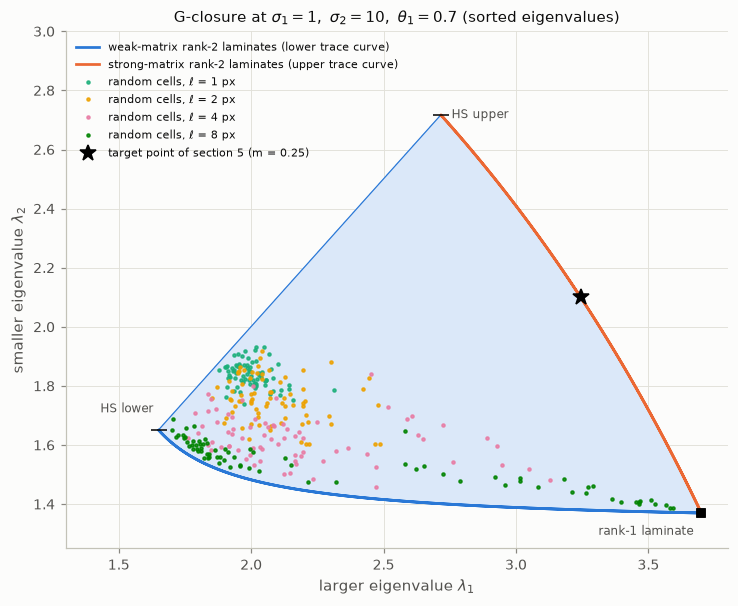

In [8]:
# --- Figure 1: the G-closure region and the random cells
fig, ax = plt.subplots(figsize=(6.6, 5.4))
ax.contourf(XA, XB, REGION.astype(float), levels=[0.5, 1.5], colors=["#dbe8f9"])
ax.contour(XA, XB, REGION.astype(float), levels=[0.5], colors=[CAT[0]], linewidths=0.8)
srt = lambda c: np.sort(c, axis=1)[:, ::-1]
ax.plot(*srt(weak_curve).T, color=CAT[0], lw=1.8, label="weak-matrix rank-2 laminates (lower trace curve)")
ax.plot(*srt(strong_curve).T, color=CAT[1], lw=1.8, label="strong-matrix rank-2 laminates (upper trace curve)")
for ie, ell in enumerate(ELLS):
    sel = [i for i, c in enumerate(cells) if c["ell"] == ell]
    ax.plot(mids[sel, 0], mids[sel, 1], ".", ms=4, color=CAT[2 + ie], alpha=0.85, label=rf"random cells, $\ell$ = {ell} px")
ax.plot([HS_LO, HS_UP], [HS_LO, HS_UP], "k_", ms=10)
ax.plot(*lam_star, "k*", ms=11, label="target point of section 5 (m = 0.25)")
ax.plot([WIENER_A, WIENER_A], [WIENER_H, WIENER_H], "ks", ms=5)
ax.text(HS_LO - 0.02, HS_LO + 0.05, "HS lower", fontsize=8, color=INK2, ha="right", va="bottom")
ax.text(HS_UP + 0.04, HS_UP + 0.0, "HS upper", fontsize=8, color=INK2, ha="left", va="center")
ax.text(WIENER_A - 0.03, WIENER_H - 0.04, "rank-1 laminate", fontsize=8, color=INK2, ha="right", va="top")
ax.set(xlabel=r"larger eigenvalue $\lambda_1$", ylabel=r"smaller eigenvalue $\lambda_2$", xlim=(1.3, 3.8), ylim=(1.25, 3.0),
       title=r"G-closure at $\sigma_1=1,\ \sigma_2=10,\ \theta_1=0.7$ (sorted eigenvalues)")
ax.legend(loc="upper left", fontsize=7.5)
plt.show()

## 3. The gradient: envelope theorem and an autodiff cross-check

For the pixel medium the Q1 value $U_{dd}(\sigma)=\min_\chi\sum_p\sigma_p\,E_p(\chi)$, with $E_p$ the energy of the field $e_d+\nabla\chi$ in pixel $p$, is a minimum of functions linear in $\sigma$, hence concave in $\sigma$, and by the envelope theorem its derivative is the energy density of the minimizer, $\partial U_{dd}/\partial\sigma_p=E_p(\chi_d)$. No adjoint solve is needed because the objective is the energy itself (the problem is self-adjoint). In terms of the nodal values $\chi_p$ of the four corners of the pixel, $E_p=h^2+2h\,g_d\cdot\chi_p+\chi_p^{\!\top}K_E\chi_p$, with $K_E$ the Q1 element stiffness (independent of $h$ in 2D), $g_d$ the integrals of $\partial_dN_a$ over the unit square, and $\sum_p\sigma_pE_p=U_{dd}$. Concavity has a consequence for design: the linearization overestimates the gain of any finite change of $\sigma$, so gradient steps on gray densities are optimistic, and only binary, certified values are reported below.

The cross-check differentiates the same minimum through a dense solve in JAX at $N=12$. The element matrices are rebuilt here by $2\times2$ Gauss quadrature of the Q1 shape functions (exact for bilinear elements) and compared with the module constants, so the check does not reuse the module's assembly. Central differences with the initial step $10^{-6}$ are compared on five pixels, and at the steps $10^{-2}$ to $10^{-7}$ (see the printout for why the initial step fails).

In [9]:
# --- the gradient: envelope theorem against automatic differentiation
import jax, jax.numpy as jnp

def q1_element_data():
    """KE = int grad N_a . grad N_b and Gint[d, a] = int dN_a/dx_d on the unit square, by 2x2 Gauss quadrature (exact for Q1)."""
    gp = (0.5 - 0.5 / np.sqrt(3), 0.5 + 0.5 / np.sqrt(3))
    corners = [(0, 0), (1, 0), (1, 1), (0, 1)]
    KE, Gint = np.zeros((4, 4)), np.zeros((2, 4))
    for x in gp:
        for y in gp:
            g = []
            for cx, cy in corners:
                fx, fy = (x if cx else 1 - x), (y if cy else 1 - y)
                g.append([(1.0 if cx else -1.0) * fy, fx * (1.0 if cy else -1.0)])
            g = np.array(g)
            KE += 0.25 * g @ g.T
            Gint += 0.25 * g.T
    return KE, Gint

KE_Q, G_Q = q1_element_data()
check("element stiffness by Gauss quadrature against cellsolver.KE (max abs difference)", np.abs(KE_Q - cs.KE).max(), 1e-14)
check("element load integrals by Gauss quadrature against cellsolver.G (max abs difference)", np.abs(G_Q - cs.G).max(), 1e-14)

N_G = 12
h_G = 1.0 / N_G
ii, jj = np.meshgrid(np.arange(N_G), np.arange(N_G), indexing="ij")
CONN = np.stack([ii * N_G + jj, ((ii + 1) % N_G) * N_G + jj, ((ii + 1) % N_G) * N_G + (jj + 1) % N_G, ii * N_G + (jj + 1) % N_G], -1).reshape(-1, 4)
ROWS, COLS = np.repeat(CONN, 4, axis=1).ravel(), np.tile(CONN, (1, 4)).ravel()


def u_dense(a, d):
    """U_dd of the periodic Q1 pixel medium a (N_G^2,) by a dense solve in JAX: min over nodal chi of the energy of e_d + grad chi."""
    K = jnp.zeros((N_G * N_G, N_G * N_G)).at[ROWS, COLS].add((a[:, None, None] * KE_Q[None]).ravel())
    f = jnp.zeros(N_G * N_G).at[CONN.ravel()].add((a[:, None] * (h_G * G_Q[d])[None, :]).ravel())
    chi = jnp.zeros(N_G * N_G).at[1:].set(jnp.linalg.solve(K[1:, 1:], -f[1:]))
    ce = chi[CONN]
    E = h_G ** 2 + 2 * h_G * (ce @ G_Q[d]) + jnp.einsum("ei,ij,ej->e", ce, KE_Q, ce)
    return jnp.sum(a * E)


a_g = cs.gaussian_threshold(N_G, 1.5, THETA, 3, (S1, S2))
U_cs, chi_g = cs.q1_effective(a_g, True)
E_env = cs.q1_energy_density(a_g, chi_g)
aj = jnp.asarray(a_g.ravel())
errs_ad, errs_u = [], []
for d in (0, 1):
    g_ad = np.asarray(jax.grad(u_dense, argnums=0)(aj, d))
    errs_ad.append(np.abs(E_env[d].ravel() - g_ad).max() / np.abs(g_ad).max())
    errs_u.append(abs(float(u_dense(aj, d)) - U_cs[d, d]) / U_cs[d, d])
print(f"N = {N_G}: U_xx = {U_cs[0,0]:.10f} (cellsolver), {float(u_dense(aj, 0)):.10f} (dense JAX); gradient entries span {E_env[0].min():.3e} to {E_env[0].max():.3e}")
check("dense JAX solve against q1_effective (max relative difference of U_xx, U_yy)", max(errs_u), 1e-12)
check("envelope gradient against jax.grad over all pixels (max relative difference, both directions)", max(errs_ad), 1e-10)

pix = [(0, 0), (3, 5), (6, 6), (9, 2), (11, 8)]
g_ad0 = np.asarray(jax.grad(u_dense, argnums=0)(aj, 0))
STEPS = (1e-2, 1e-3, 1e-4, 1e-5, 1e-6, 1e-7)
fd_val = {st: [] for st in STEPS}
for (i, j) in pix:
    for st in STEPS:
        a_p, a_m = a_g.copy(), a_g.copy()
        a_p[i, j] += st
        a_m[i, j] -= st
        fd_val[st].append((cs.q1_effective(a_p)[0, 0] - cs.q1_effective(a_m)[0, 0]) / (2 * st))
print(f"{'pixel':>8s} {'sigma':>6s} {'envelope':>14s} {'jax.grad':>14s} {'FD, step 1e-6':>14s} {'FD, step 1e-4':>14s}")
for k, (i, j) in enumerate(pix):
    print(f"({i:2d},{j:2d})  {a_g[i, j]:6.1f} {E_env[0, i, j]:14.8e} {g_ad0[i * N_G + j]:14.8e} {fd_val[1e-6][k]:14.8e} {fd_val[1e-4][k]:14.8e}")
fd_err = {st: max(abs(fd_val[st][k] - E_env[0, i, j]) / E_env[0, i, j] for k, (i, j) in enumerate(pix)) for st in STEPS}
print("max relative difference to the envelope gradient over the 5 pixels, by step:", ", ".join(f"{st:.0e}: {fd_err[st]:.2e}" for st in STEPS))
print(f"  (rounding of the difference quotient: eps U / (step E) = {np.finfo(float).eps * U_cs[0, 0] / (1e-6 * min(E_env[0, i, j] for i, j in pix)):.1e} at step 1e-6 for the smallest entry)")
# The initial step 1e-6 is limited by rounding on the small entries (strong pixels): the difference quotient of two numbers of size U
# loses eps U/step. Step 1e-4 balances rounding (right branch of the scan) against the O(step^2) truncation (left branch); the tolerance 1e-6 is the initial one.
check("envelope gradient against central differences, step 1e-4 (max relative difference, 5 pixels)", fd_err[1e-4], 1e-6)
check_in("the step scan is V-shaped: the smallest error is at an interior step (index in the scan 1e-2 ... 1e-7; truncation on the left, rounding on the right)",
         float(np.argmin([fd_err[st] for st in STEPS])), 1.0, float(len(STEPS) - 2))
id_err = max(abs((a_g * E_env[d]).sum() - U_cs[d, d]) / U_cs[d, d] for d in (0, 1))
check("energy identity sum_p sigma_p E_p = U_dd (max relative difference, both directions)", id_err, 1e-12)

PASS  element stiffness by Gauss quadrature against cellsolver.KE (max abs difference): got 1.11022e-16, target 0, |diff| 1.11e-16 <= 1e-14
PASS  element load integrals by Gauss quadrature against cellsolver.G (max abs difference): got 5.55112e-17, target 0, |diff| 5.55e-17 <= 1e-14


N = 12: U_xx = 1.7512875476 (cellsolver), 1.7512875476 (dense JAX); gradient entries span 1.386e-04 to 5.098e-02
PASS  dense JAX solve against q1_effective (max relative difference of U_xx, U_yy): got 2.02863e-15, target 0, |diff| 2.03e-15 <= 1e-12
PASS  envelope gradient against jax.grad over all pixels (max relative difference, both directions): got 2.722e-15, target 0, |diff| 2.72e-15 <= 1e-10
   pixel  sigma       envelope       jax.grad  FD, step 1e-6  FD, step 1e-4
( 0, 0)     1.0 1.91210773e-03 1.91210773e-03 1.91210747e-03 1.91210773e-03
( 3, 5)     1.0 1.11728439e-02 1.11728439e-02 1.11728439e-02 1.11728439e-02
( 6, 6)     1.0 1.45142305e-02 1.45142305e-02 1.45142300e-02 1.45142305e-02
( 9, 2)    10.0 2.41498284e-04 2.41498284e-04 2.41497933e-04 2.41498285e-04
(11, 8)    10.0 7.76081197e-04 7.76081197e-04 7.76081310e-04 7.76081194e-04
max relative difference to the envelope gradient over the 5 pixels, by step: 1e-02: 1.45e-05, 1e-03: 1.45e-07, 1e-04: 4.48e-09, 1e-05: 2.48e-07,

## 4. The isotropic maximum: does one periodic inclusion reach Hashin-Shtrikman?

**Two predictions.** P1 (Vigdergauz in elasticity; Liu, James and Leo 2007, who construct periodic E-inclusions, which in 2D coincide with Vigdergauz's shapes; and Liu 2010, who shows that a periodic microstructure attains an HS bound if and only if it is a periodic E-inclusion, conductive composites included): a single periodic inclusion with uniform interior field attains $\mathrm{HS_{up}}$, so the certified gap tends to 0 with $N$ and the interior field becomes uniform. P2 (the opposite, relaxation-based hypothesis): a single scale cannot attain HS, and the gap saturates at some $g_\infty>0$ or the designs develop ever finer structure. P2 comes with no numerical value of $g_\infty$. A certified gap that decreases with $N$ does not discriminate: under P2 the certified gap also falls, because the Q1 bracket narrows. So the criterion used here is the certified *interval* of the gap, with the weak-disk and weak-square controls at the same $N$, and the conclusion that can be drawn is only "single-scale designs of this pixel family come within $x$ of HS", with $x$ the upper end of the interval at the largest $N$.

**Pipeline.** A density $\rho$ symmetric under the eight symmetries of the square (C4v) is filtered with a periodic cone filter of radius 2 pixels, projected by $P(x)=\dfrac{\tanh\beta\eta+\tanh\beta(x-\eta)}{\tanh\beta\eta+\tanh\beta(1-\eta)}$ with the threshold $\eta$ found by bisection so that the strong fraction is exactly 0.3, and interpolated by $\sigma=\sigma_1+(\sigma_2-\sigma_1)P^3$. The objective is $\tfrac12(U_{xx}+U_{yy})$ (equal for symmetric designs): the optimizer maximizes the primal upper bound $U$, while every gap below is certified from the other end of the bracket, $L$ (its upper end) and $U$ (its lower end). The two differ, and it is not claimed that this difference is harmless. The gradient is the envelope gradient $E_p$ pushed back through the interpolation, the projection (including the dependence of $\eta$ on $\rho$ through the volume constraint: $\mathrm{d}J/\mathrm{d}x_i=P'_i\,(v_i-\sum_jv_jP_{\eta,j}/\sum_jP_{\eta,j})$ with $v=\partial J/\partial P$), and the self-adjoint filter, and is symmetrized over the group. Adam with step 0.05 ascends, the density is clipped to $[0,1]$, and the projection sharpness is continued through $\beta=1,2,4,8,16,32$ with 40 iterations each. The final design is binarized by rank on whole symmetry orbits so that the weak pixel count is the nearest attainable to $0.7N^2$ (within $8/N^2$); the HS bounds are recomputed at the actual fraction. The first cell below checks the full gradient chain against central differences at $\beta=1$, 8 and 32.

In [10]:
# --- the design pipeline: symmetric density, cone filter, tanh projection with a volume-preserving threshold, Adam
def images(x, group):
    """Average over the images of the pixel grid under the symmetry group (D2: mirrors in x and y; C4v: the 8 elements of D4)."""
    fl = [x, x[::-1, :], x[:, ::-1], x[::-1, ::-1]]
    if group == "C4v":
        fl += [t.T for t in fl]
    return sum(fl) / len(fl)


def cone_kernel_hat(N, r=2.0):
    """rfft2 of the periodic cone filter of radius r pixels (weights max(0, r - |d|), normalized): self-adjoint."""
    d = np.minimum(np.arange(N), N - np.arange(N))
    K = np.maximum(0.0, r - np.hypot(d[:, None], d[None, :]))
    return np.fft.rfft2(K / K.sum())


def filt(x, Kh):
    return np.fft.irfft2(np.fft.rfft2(x) * Kh, s=x.shape)


def project(x, eta, beta):
    ta, tb = np.tanh(beta * eta), np.tanh(beta * (1 - eta))
    return (ta + np.tanh(beta * (x - eta))) / (ta + tb)


def dproject(x, eta, beta):
    """(P, dP/dx, dP/deta) of the tanh projection."""
    ta, tb = np.tanh(beta * eta), np.tanh(beta * (1 - eta))
    den = ta + tb
    t = np.tanh(beta * (x - eta))
    dnum = beta * (1 - ta ** 2) - beta * (1 - t ** 2)
    dden = beta * (1 - ta ** 2) - beta * (1 - tb ** 2)
    return (ta + t) / den, beta * (1 - t ** 2) / den, (dnum * den - (ta + t) * dden) / den ** 2


def find_eta(x, beta, target):
    """Threshold eta (bisection) such that the mean of the projected density equals target (the strong fraction)."""
    lo, hi = 0.0, 1.0
    for _ in range(60):
        mid = 0.5 * (lo + hi)
        lo, hi = (mid, hi) if project(x, mid, beta).mean() > target else (lo, mid)
    return 0.5 * (lo + hi)


def design_step(rho, Kh, beta, target, group, wy):
    """Objective J and its gradient wrt the density rho (rho = 1 is the strong phase; sigma = S1 + (S2 - S1) rho_p^3).

    C4v: J = (U_xx + U_yy)/2; D2: J = U_xx + wy U_yy. The gradient is dJ/dsigma_p = E_p (envelope theorem) pushed through
    the projection, including the dependence of the threshold eta on the density (volume constraint), and the self-adjoint filter.
    """
    xf = filt(rho, Kh)
    eta = find_eta(xf, beta, target)
    P, dx, de = dproject(xf, eta, beta)
    sig = S1 + (S2 - S1) * P ** 3
    U, chi = cs.q1_effective(sig, True)
    E = cs.q1_energy_density(sig, chi)
    if group == "C4v":
        J, g = 0.5 * (U[0, 0] + U[1, 1]), 0.5 * (E[0] + E[1])
    else:
        J, g = U[0, 0] + wy * U[1, 1], E[0] + wy * E[1]
    v = g * 3 * (S2 - S1) * P ** 2
    gx = dx * (v - (v * de).sum() / de.sum())              # implicit derivative of eta from mean(P) = target
    return J, images(filt(gx, Kh), group)


def optimize(rho, N, group, wy, betas, iters, target=1 - THETA, step=0.05):
    """Adam ascent with projection steepness continuation; the density is clipped to [0, 1] and symmetrized each step."""
    Kh = cone_kernel_hat(N)
    rho = images(rho, group).clip(0, 1)
    for beta in betas:
        m1, m2 = np.zeros_like(rho), np.zeros_like(rho)
        for it in range(1, iters + 1):
            J, g = design_step(rho, Kh, beta, target, group, wy)
            m1 = 0.9 * m1 + 0.1 * g
            m2 = 0.999 * m2 + 0.001 * g * g
            rho = images(rho + step * (m1 / (1 - 0.9 ** it)) / (np.sqrt(m2 / (1 - 0.999 ** it)) + 1e-8), group).clip(0, 1)
    return rho, J


def binarize(rho, N, group, target_weak=THETA, beta=64.0):
    """Binary design (True = strong) by rank on whole symmetry orbits; the weak pixel count is the one nearest target_weak N^2."""
    xf = filt(rho, cone_kernel_hat(N))
    P = project(xf, find_eta(xf, beta, 1 - target_weak), beta).ravel()
    lab = orbit_labels(N, group)
    orb = np.unique(lab)
    size = np.bincount(lab, minlength=N * N)[orb]
    val = np.bincount(lab, weights=P, minlength=N * N)[orb] / size
    order = np.argsort(val, kind="stable")                     # weakest orbits first
    cum, tgt = np.cumsum(size[order]), target_weak * N * N
    k = int(np.searchsorted(cum, tgt))
    if k > 0 and abs(cum[k - 1] - tgt) < abs(cum[k] - tgt):
        k -= 1
    return ~np.isin(lab, orb[order[:k + 1]]).reshape(N, N)


sigma_of = lambda strong: np.where(strong, S2, S1)
up2 = lambda a: np.kron(a, np.ones((2, 2), dtype=a.dtype))


def certify(strong):
    """Certified bracket of the pixel medium at N and at 2N (2x2 replication, nested); the 2N bracket is the one reported."""
    s = sigma_of(strong)
    L1, U1 = cs.q1_bracket(s)
    L2, U2 = cs.q1_bracket(up2(s))
    return dict(strong=strong, th=1 - strong.mean(), L1=L1, U1=U1, L=L2, U=U2)


def field_cv(strong, erode=0, vector=True):
    """Coefficient of variation of the field e_x + grad chi_x over the weak pixels (element-centered gradients); erode > 0 drops
    weak pixels within `erode` pixels (4-neighborhood, periodic) of the interface.
    vector=True: sqrt(var F_x + var F_y) / |mean F| (both components; an E-inclusion has a constant vector field);
    vector=False: std(|F|) / mean(|F|) of the magnitude only, which is blind to variation of the direction."""
    U, chi = cs.q1_effective(sigma_of(strong), True)
    F = cs.q1_center_field(chi, 0)
    core = ~strong
    for _ in range(erode):
        core = core & np.roll(core, 1, 0) & np.roll(core, -1, 0) & np.roll(core, 1, 1) & np.roll(core, -1, 1)
    if vector:
        Fx, Fy = F[0][core], F[1][core]
        return np.sqrt(Fx.var() + Fy.var()) / np.hypot(Fx.mean(), Fy.mean())
    mag = np.hypot(F[0], F[1])
    return mag[core].std() / mag[core].mean()

# the gradient of the whole chain (filter, projection with eta, interpolation, Q1 solve) against central differences
N_T = 32
rho_t = images(0.3 + 0.05 * np.random.default_rng(0).standard_normal((N_T, N_T)), "C4v").clip(0, 1)
Kh_t = cone_kernel_hat(N_T)
fd_rel = []
for beta_t in (1.0, 8.0, 32.0):
    J_t, g_t = design_step(rho_t, Kh_t, beta_t, 1 - THETA, "C4v", 0.0)
    for (i, j) in [(3, 5), (10, 2), (15, 15)]:
        dirn = np.zeros((N_T, N_T)); dirn[i, j] = 1.0
        dirn = images(dirn, "C4v") * 8                         # orbit indicator
        Jp = design_step(rho_t + 1e-6 * dirn, Kh_t, beta_t, 1 - THETA, "C4v", 0.0)[0]
        Jm = design_step(rho_t - 1e-6 * dirn, Kh_t, beta_t, 1 - THETA, "C4v", 0.0)[0]
        fd_rel.append(abs((Jp - Jm) / 2e-6 - (g_t * dirn).sum()) / abs((g_t * dirn).sum()))
print(f"gradient of the whole design chain at N = {N_T}, beta = 1, 8 and 32, 3 orbits each: relative difference to central FD {min(fd_rel):.1e} to {max(fd_rel):.1e}")
check_in("design-chain gradient against central differences, step 1e-6 (max relative difference)", max(fd_rel), 0.0, 1e-5)

gradient of the whole design chain at N = 32, beta = 1, 8 and 32, 3 orbits each: relative difference to central FD 6.5e-09 to 3.7e-07
PASS  design-chain gradient against central differences, step 1e-6 (max relative difference): got 3.6572e-07, required in [0, 1e-05]


**Runs.** Four starts at $N=32$ and $N=64$, 240 iterations each: (i) the weak disk $R=0.4720$, (ii) the weak square of side $\approx0.8367$ (even side, to keep the C4v symmetry), (iii, iv) $\rho=0.3+0.05\,\xi$ with $\xi$ standard normal, seeds 0 and 1. At $N=128$ the best $N=64$ design is upsampled $2\times2$ and used as the warm start of one chain (continuation $\beta=4,8,16,32$, 160 iterations). The Hamming change between a design and its upsampled parent measures how far the warm-started optimizer moves; it is not a measure of the structure that independent runs at each $N$ would find. Every design is certified at $N$ and at $2N$ and the $2N$ bracket is the one reported. Controls at each $N$, certified the same way: the weak disk $R=0.472$ and the pixel-aligned weak square of side $\mathrm{round}(0.8367N)$ (odd at $N=32$ and 128, so not C4v-centered, and at fraction 0.7119 for $N=32$, 64); the Rayleigh value of the weak-disk array at the control's pixel fraction is printed beside the disk. The square start at $N=32$ (side 26, weak fraction 0.6602) is certified separately. Two reference computations at $N=128$: weak superellipses $|x|^p+|y|^p<R^p$ ($p=4,6,8,12$; $p=2$ is the disk and $p\to\infty$ the square) with the weak pixel count of the optimized design, certified at $2N$, which test the role of rounding the corners and give the field statistic of a smooth shape sampled on the same staircase; and a restart of the best $N=64$ design for 160 further iterations, which tests convergence in the number of iterations. The statistic that describes the interior field is the coefficient of variation (CV) of the vector field $e_x+\nabla\chi_x$ over the weak pixels (element-centered gradients): $\sqrt{\operatorname{var}F_x+\operatorname{var}F_y}/|\overline F|$, which an E-inclusion has equal to zero (a constant vector field); it is given over all weak pixels and with a layer of two pixels at the interface removed. The CV of the magnitude $|F|$ alone, which is blind to variation of direction, is printed for comparison.

In [11]:
# --- section 4: C4v designs at N = 32, 64, 128, all certified
T_C4 = time.perf_counter()
BETAS = (1, 2, 4, 8, 16, 32)
BETAS_WARM = (4, 8, 16, 32)

def start_density(N, kind):
    if kind == "disk":
        return cs.disk_pixels(N, 0.4720, 0.0, 1.0)                                  # weak disk (rho = 0) in a strong matrix
    if kind == "square":
        return cs.square_pixels(N, 2 * int(round(0.8367 * N / 2)), 0.0, 1.0)         # even side keeps the C4v symmetry
    return (0.3 + 0.05 * np.random.default_rng(kind).standard_normal((N, N))).clip(0, 1)


def gap_iso(c):
    """Certified interval of the gap (HS_up - sigma*_xx)/(HS_up - HS_lo) of an isotropic design at its own fraction."""
    lo, hi = bd.hs2d(S1, S2, c["th"])
    rng_ = hi - lo
    return max(0.0, (hi - c["U"][0, 0]) / rng_), (hi - c["L"][0, 0]) / rng_


D4 = {32: [], 64: [], 128: []}
def run_c4(N, kind, rho0, betas, iters):
    t = time.perf_counter()
    rho, Jg = optimize(rho0, N, "C4v", 0.0, betas, iters)
    c = certify(binarize(rho, N, "C4v"))
    c.update(N=N, kind=kind, gap=gap_iso(c), cv=field_cv(c["strong"]), cv_core=field_cv(c["strong"], 2), cvs=field_cv(c["strong"], 0, False), cvs_core=field_cv(c["strong"], 2, False),
             Jgray=Jg, secs=time.perf_counter() - t, parent=None)
    D4[N].append(c)
    return c

for N, its in ((32, 40), (64, 40)):
    for kind in ("disk", "square", 0, 1):
        run_c4(N, kind, start_density(N, kind), BETAS, its)
    print(f"N = {N}: 4 starts done, {sum(c['secs'] for c in D4[N]):.1f} s")

def best_of(N):
    return sorted(D4[N], key=lambda c: c["gap"][1])

# N = 128: warm start from the best N = 64 design, upsampled 2x2 (one chain)
for rank, par in enumerate(best_of(64)[:1]):
    c = run_c4(128, f"warm from N = 64 ({par['kind']})", up2(par["strong"]).astype(float), BETAS_WARM, 40)
    c["parent"] = par
    c["ham"] = np.mean(c["strong"] != up2(par["strong"]))
print(f"N = 128: 1 warm start done, {sum(c['secs'] for c in D4[128]):.1f} s")
print(f"C4v designs: {time.perf_counter() - T_C4:.1f} s")

# controls at the same N, certified the same way
CTRL = {}
for N in (32, 64, 128):
    side = int(round(0.8367 * N))
    for nm, a in (("weak disk R = 0.472", cs.disk_pixels(N, 0.472, S1, S2)), (f"weak square side {side}", cs.square_pixels(N, side, S1, S2))):
        c = certify(a == S2)
        c.update(N=N, kind=nm, gap=gap_iso(c), cv=field_cv(c["strong"]), cv_core=field_cv(c["strong"], 2), cvs=field_cv(c["strong"], 0, False), cvs_core=field_cv(c["strong"], 2, False))
        CTRL.setdefault(N, []).append(c)
        if "disk" in nm:
            c["rayleigh"] = rayleigh_disk_weak(c["th"])
print(f"controls done, {time.perf_counter() - T_C4:.1f} s in total for this section")

# the N = 32 square start (side 26, even so that it keeps C4v), certified, to compare with the design the optimizer made of it
st32 = start_density(32, "square") == 1.0
START32 = certify(st32)
START32["gap"] = gap_iso(START32)

# smooth-shape reference at N = 128: weak superellipses |x|^p + |y|^p < R^p (p = 2 disk, p -> infinity square) at the best design's pixel count,
# certified at 2N only. This tests whether rounding the corners of a square does what the optimizer's design does, and gives the CV of a
# staircase-sampled smooth shape (the discretization floor of the field statistic) at the same N.
def superellipse_strong(N, p, n_weak):
    x = (np.arange(N) + 0.5) / N - 0.5
    X, Y = np.meshgrid(x, x, indexing="ij")
    r = ((np.abs(X) ** p + np.abs(Y) ** p) ** (1.0 / p)).ravel()
    srt_ = np.sort(r)
    return (r >= 0.5 * (srt_[n_weak - 1] + srt_[n_weak])).reshape(N, N)

SUPER = []
n_weak_128 = int(round(D4[128][0]["th"] * 128 ** 2))                              # weak pixel count of the N = 128 design
for p_exp in (4, 6, 8, 12):
    st = superellipse_strong(128, p_exp, n_weak_128)
    L_, U_ = cs.q1_bracket(up2(sigma_of(st)))
    c = dict(strong=st, th=1 - st.mean(), L=L_, U=U_, p=p_exp)
    c.update(gap=gap_iso(c), cv=field_cv(st), cv_core=field_cv(st, 2), cvs=field_cv(st, 0, False), cvs_core=field_cv(st, 2, False))
    SUPER.append(c)
print(f"superellipses done, {time.perf_counter() - T_C4:.1f} s in total for this section")

# convergence in iterations at N = 64: restart the binary best design at beta = 4 and continue for 160 iterations
b64_start = best_of(64)[0]
rho_cont, _ = optimize(b64_start["strong"].astype(float), 64, "C4v", 0.0, BETAS_WARM, 40)
CONT = certify(binarize(rho_cont, 64, "C4v"))
CONT["gap"] = gap_iso(CONT)
CONT["ham"] = np.mean(CONT["strong"] != b64_start["strong"])
print(f"restart of the best N = 64 design for 160 more iterations done, {time.perf_counter() - T_C4:.1f} s in total for this section")

N = 32: 4 starts done, 3.3 s


N = 64: 4 starts done, 17.3 s


N = 128: 1 warm start done, 16.6 s
C4v designs: 37.2 s


controls done, 41.7 s in total for this section


superellipses done, 48.8 s in total for this section


restart of the best N = 64 design for 160 more iterations done, 51.7 s in total for this section


In [12]:
print("certified C4v designs (bracket of the pixel medium at 2N; gap = (HS_up - sigma*_xx)/(HS_up - HS_lo) at the design's own fraction)")
print(f"{'N':>4s} {'start':>26s} {'weak frac':>9s} {'L_xx':>8s} {'U_xx':>8s} {'HS_up':>8s} {'gap, lower end':>14s} {'gap, upper end':>14s} {'CV vec':>7s} {'core':>6s}")
for N in (32, 64, 128):
    for c in D4[N]:
        print(f"{N:4d} {str(c['kind']):>26s} {c['th']:9.4f} {c['L'][0,0]:8.5f} {c['U'][0,0]:8.5f} {bd.hs2d(S1, S2, c['th'])[1]:8.5f} {100*c['gap'][0]:13.2f}% {100*c['gap'][1]:13.2f}% {c['cv']:7.3f} {c['cv_core']:6.3f}")
    for c in CTRL[N]:
        extra = f"   (Rayleigh {c['rayleigh']:.5f})" if "rayleigh" in c else ""
        print(f"{N:4d} {'control: ' + c['kind']:>26s} {c['th']:9.4f} {c['L'][0,0]:8.5f} {c['U'][0,0]:8.5f} {bd.hs2d(S1, S2, c['th'])[1]:8.5f} {100*c['gap'][0]:13.2f}% {100*c['gap'][1]:13.2f}% {c['cv']:7.3f} {c['cv_core']:6.3f}{extra}")
for c in SUPER:
    print(f"{128:4d} {'smooth reference: superellipse p = ' + str(c['p']):>26s} {c['th']:9.4f} {c['L'][0,0]:8.5f} {c['U'][0,0]:8.5f} {bd.hs2d(S1, S2, c['th'])[1]:8.5f} {100*c['gap'][0]:13.2f}% {100*c['gap'][1]:13.2f}% {c['cv']:7.3f} {c['cv_core']:6.3f}")
SQ32 = [c for c in D4[32] if c["kind"] == "square"][0]
print(f"N = 32: the square start (side 26, fraction {START32['th']:.4f}) is certified at gap [{100*START32['gap'][0]:.2f}%, {100*START32['gap'][1]:.2f}%]; the optimizer turned it into [{100*SQ32['gap'][0]:.2f}%, {100*SQ32['gap'][1]:.2f}%]")
print(f"N = 64: restarting the best design for 160 more iterations (beta = 4, 8, 16, 32): gap [{100*CONT['gap'][0]:.2f}%, {100*CONT['gap'][1]:.2f}%] against [{100*b64_start['gap'][0]:.2f}%, {100*b64_start['gap'][1]:.2f}%]; Hamming change {100*CONT['ham']:.2f}% of the pixels")

certified C4v designs (bracket of the pixel medium at 2N; gap = (HS_up - sigma*_xx)/(HS_up - HS_lo) at the design's own fraction)
   N                      start weak frac     L_xx     U_xx    HS_up gap, lower end gap, upper end  CV vec   core
  32                       disk    0.7031  2.64030  2.64789  2.69612          4.57%          5.29%   0.110  0.051
  32                     square    0.7031  2.46437  2.49461  2.69612         19.11%         21.98%   0.224  0.062
  32                          0    0.6992  2.56746  2.61650  2.72193          9.86%         14.45%   0.154  0.068
  32                          1    0.6992  2.64622  2.66204  2.72193          5.60%          7.08%   0.120  0.066
  32 control: weak disk R = 0.472    0.6992  2.42241  2.43684  2.72193         26.67%         28.02%   0.268  0.194   (Rayleigh 2.46864)
  32 control: weak square side 27    0.7119  2.60820  2.61085  2.63843          2.70%          2.96%   0.085  0.044
  64                       disk    0.6992  2.47

In [13]:
# --- checks of section 4
allc = [c for N in D4 for c in D4[N]] + [c for N in CTRL for c in CTRL[N]]
min_up = min(bd.hs2d(S1, S2, c["th"])[1] - c["L"][0, 0] for c in allc)
min_lo = min(c["U"][0, 0] - bd.hs2d(S1, S2, c["th"])[0] for c in allc)
min_nest = min(min(c["L"][0, 0] - c["L1"][0, 0], c["U1"][0, 0] - c["U"][0, 0]) for c in allc)
n_viol_c4 = sum(bd.certified_violation(c["L"], c["U"], S1, S2, c["th"]) for c in allc)
print(f"{len(allc)} certified designs and controls: smallest HS_up - L_xx = {min_up:.4f}; certified violations of the G-closure {n_viol_c4}; "
      f"smallest U_xx - HS_lo = {min_lo:.4f} (printed only: designs maximize sigma_xx, so this margin is large by construction); nesting (2N inside N) margin {min_nest:.2e}")
# The one check here that can fail for a substantive reason is the rigor of the upper end, L_xx <= HS_up (a theorem for an isotropic tensor, so a certified bracket cannot exceed it).
check_in("rigor: L_xx(2N) <= HS_up at the design's fraction, every design (min slack)", min_up, -1e-12, np.inf)
# The next three are unit tests of the implementation (interface identities and constructions), not evidence about the optimization.
check_in("unit test: the 2N bracket lies inside the N bracket (min margin over designs)", min_nest, -1e-12, np.inf)
check_in("unit test: C4v designs are isotropic: |U_xx - U_yy| and |U_xy| (max over designs, at 2N)", max(max(abs(c["U"][0, 0] - c["U"][1, 1]), abs(c["U"][0, 1])) for c in allc), 0.0, 1e-10)
check_in("construction: weak fraction of every design within 8/N^2 of 0.7 (max of |theta - 0.7| N^2 / 8)", max(abs(c["th"] - THETA) * c["N"] ** 2 / 8 for N in D4 for c in D4[N]), 0.0, 1.0)

# best optimizer output at each N, and the best of optimizer outputs and controls (the controls are part of what the optimizer has to beat)
b32, b64, b128 = best_of(32)[0], best_of(64)[0], best_of(128)[0]
best_any = {n: min(D4[n] + CTRL[n], key=lambda c: c["gap"][1]) for n in (32, 64, 128)}
hs128 = bd.hs2d(S1, S2, b128["th"])[1]
ray128 = rayleigh_disk_weak(b128["th"])
print(f"best certified L_xx at N = 128: {b128['L'][0,0]:.5f}; Rayleigh weak-disk array at the same fraction {ray128:.5f}; HS_up {hs128:.5f}")
print("certified gap, upper end, best optimizer output at each N :", ", ".join(f"N = {n}: {100*b['gap'][1]:.2f}%" for n, b in ((32, b32), (64, b64), (128, b128))))
print("certified gap, lower end, the same designs                :", ", ".join(f"N = {n}: {100*b['gap'][0]:.2f}%" for n, b in ((32, b32), (64, b64), (128, b128))))
print("best of optimizer outputs and controls at each N (upper end):", ", ".join(f"N = {n}: {100*best_any[n]['gap'][1]:.2f}% ({best_any[n]['kind']})" for n in (32, 64, 128)))
print("descriptive trend: the best optimizer output is worse than the weak-square control at N = 32 and better at N = 64 and 128; the decrease with N of the table is not a test of P1 against P2")
for c in D4[128]:
    print(f"chain from the N = 64 design '{c['parent']['kind']}': upper end of the gap {100*c['parent']['gap'][1]:.2f}% at N = 64 -> {100*c['gap'][1]:.2f}% at N = 128 (Hamming change {100*c['ham']:.2f}% of the pixels)")
# like for like: every control against HS_up at its own fraction
for c in CTRL[128]:
    hs_c = bd.hs2d(S1, S2, c["th"])[1]
    print(f"N = 128 {c['kind']}: certified L_xx {c['L'][0,0]:.5f} is {100*(hs_c - c['L'][0,0])/hs_c:.2f}% below HS_up at its own fraction ({hs_c:.5f})")
print(f"N = 128 best design: certified interval [{b128['L'][0,0]:.5f}, {b128['U'][0,0]:.5f}], L_xx is {100*(hs128 - b128['L'][0,0])/hs128:.2f}% below HS_up = {hs128:.5f} at its own fraction")
ray_ref = rayleigh_disk_weak(THETA)
print(f"single-scale reference: Rayleigh weak-disk array at theta = 0.7: {ray_ref:.5f}, {100*(HS_UP - ray_ref)/(HS_UP - HS_LO):.2f}% of the HS range below HS_up")
print("weak-disk control, certified gap upper end:", ", ".join(f"N = {n}: {100*CTRL[n][0]['gap'][1]:.2f}%" for n in (32, 64, 128)))
print("weak-square control, certified gap interval:", ", ".join(f"N = {n}: [{100*CTRL[n][1]['gap'][0]:.2f}%, {100*CTRL[n][1]['gap'][1]:.2f}%]" for n in (32, 64, 128)))
print("Rayleigh value against the certified bracket of the pixel disk control:", ", ".join(
    f"N = {n}: {CTRL[n][0]['rayleigh']:.5f} in [{CTRL[n][0]['L'][0,0]:.5f}, {CTRL[n][0]['U'][0,0]:.5f}]: {'yes' if CTRL[n][0]['L'][0,0] <= CTRL[n][0]['rayleigh'] <= CTRL[n][0]['U'][0,0] else 'no'}" for n in (32, 64, 128)))
check_in("the exact (Rayleigh) weak-disk array lies inside the N = 128 certified bracket of the pixel disk (value)", CTRL[128][0]["rayleigh"], CTRL[128][0]["L"][0, 0], CTRL[128][0]["U"][0, 0])
# headline: the optimized design against the pixel-aligned weak square (the best single-scale competitor), at N = 128
check_in("headline, N = 128: the best design's gap (upper end) is below the weak-square control's gap (lower end) (difference)", CTRL[128][1]["gap"][0] - b128["gap"][1], 0.0, np.inf)
print("smooth reference, superellipses at N = 128 (certified gap interval): " + ", ".join(f"p = {c['p']}: [{100*c['gap'][0]:.2f}%, {100*c['gap'][1]:.2f}%]" for c in SUPER))
cv_o, cv_d, cv_s = b128["cv"], CTRL[128][0]["cv"], CTRL[128][1]["cv"]
sup_best = min(SUPER, key=lambda c: c["gap"][1])
print(f"vector CV of e_x + grad chi_x (both components) at N = 128: optimized {cv_o:.4f}, weak square {cv_s:.4f}, weak disk {cv_d:.4f}, best superellipse (p = {sup_best['p']}) {sup_best['cv']:.4f};"
      f"  interface layer removed (2 px): {b128['cv_core']:.4f}, {CTRL[128][1]['cv_core']:.4f}, {CTRL[128][0]['cv_core']:.4f}, {sup_best['cv_core']:.4f}")
print(f"CV of the magnitude |e_x + grad chi_x| only, at N = 128: optimized {b128['cvs']:.4f}, weak square {CTRL[128][1]['cvs']:.4f}, weak disk {CTRL[128][0]['cvs']:.4f}, superellipse p = {sup_best['p']} {sup_best['cvs']:.4f}"
      f" (the statistic of an earlier version)")
print("vector CV at N = 32, 64 for the best optimizer output and the weak square control:", ", ".join(f"N = {n}: {b['cv']:.3f} and {CTRL[n][1]['cv']:.3f}" for n, b in ((32, b32), (64, b64))))
# descriptive orderings at N = 128 only (fixed after seeing the run; listed in the caveats)
check_in("descriptive, N = 128 only: vector CV(optimized) < CV(weak square) (difference)", cv_s - cv_o, 0.0, np.inf)
check_in("descriptive, N = 128 only: vector CV(weak square) < CV(weak disk) (difference; the opposite order was expected)", cv_d - cv_s, 0.0, np.inf)
print("N = 64 best against the upsampled N = 32 best (independent runs, not a refinement): Hamming", f"{100*np.mean(b64['strong'] != up2(b32['strong'])):.1f}%")

15 certified designs and controls: smallest HS_up - L_xx = 0.0072; certified violations of the G-closure 0; smallest U_xx - HS_lo = 0.7840 (printed only: designs maximize sigma_xx, so this margin is large by construction); nesting (2N inside N) margin 3.10e-04
PASS  rigor: L_xx(2N) <= HS_up at the design's fraction, every design (min slack): got 0.0071523, required in [-1e-12, inf]
PASS  unit test: the 2N bracket lies inside the N bracket (min margin over designs): got 0.000310067, required in [-1e-12, inf]
PASS  unit test: C4v designs are isotropic: |U_xx - U_yy| and |U_xy| (max over designs, at 2N): got 1.86517e-14, required in [0, 1e-10]
PASS  construction: weak fraction of every design within 8/N^2 of 0.7 (max of |theta - 0.7| N^2 / 8): got 0.4, required in [0, 1]
best certified L_xx at N = 128: 2.70832; Rayleigh weak-disk array at the same fraction 2.46036; HS_up 2.71547
certified gap, upper end, best optimizer output at each N : N = 32: 5.29%, N = 64: 1.01%, N = 128: 0.67%
certif

**Reading the table.** The interval is the quantity that carries the argument. At $N=128$ the best design has a certified gap of $[0.55\%,0.67\%]$ of the HS range; the weak disk, the single-scale design that P2 had in mind, is at 23.85% (the Rayleigh value of the true disk array at $\theta_1=0.7$ is 23.89% of the range below $\mathrm{HS_{up}}$, the like-for-like single-scale reference; the pixel disk at the control's own fraction is 9.37% below its $\mathrm{HS_{up}}$) and the pixel-aligned weak square at $[2.94\%,2.97\%]$. The best design at each $N$ has to include the controls: at $N=32$ the best of all is the weak square at 2.96%, better than every optimizer output (best 5.29%), and the optimizer's own square start (side 26, certified at $[3.21\%,3.46\%]$ at its own fraction 0.6602) was turned into $[19.11\%,21.98\%]$, so the pipeline can destroy a good start. At $N=64$ and 128 the best optimizer output beats the weak square (1.01% against a lower end of 2.78% at $N=64$; 0.67% against 2.94% at $N=128$); the headline check is at $N=128$. The best optimizer output falls with $N$ (upper ends 5.29%, 1.01%, 0.67%) and along the warm chain from $N=64$ to 128 (1.01% to 0.67%), but this descriptive trend mixes a start effect (the $N=32$ output is worse than a control) with the resolution, and the same decrease would hold under P2, so it is not used as evidence. What the certified numbers do give is a bound: for periodic pixel cells with 128 pixels at weak fraction 0.7002, any single-scale saturation level above 0.67% of the HS range is excluded (0.26% below $\mathrm{HS_{up}}$ in absolute terms). This is a statement about this pixel family at this resolution, not about the limit $N\to\infty$. The lower end of the interval is positive at every $N$, as expected for a staircase medium; it is not used as evidence that the limit shape misses HS.

Four observations qualify this. First, the optimizer is not reliable: over the starts at $N=32$ and 64 the upper ends of the gap run from 5.29% to 22.98%, except the square start at $N=64$ (1.01%); the disk start at $N=64$ ends at 22.98%, little better than the pixel disk itself (26.07%). Second, rounding the corners does what the optimizer's design does, in this family: the weak square's gap does not depend on $N$ (2.96%, 2.87%, 2.97%; it is a fixed shape), and the smooth superellipses at $N=128$ and at the same pixel count have gap intervals $[2.53\%,2.74\%]$ ($p=4$), $[0.76\%,0.91\%]$ ($p=6$), $[0.54\%,0.66\%]$ ($p=8$) and $[0.87\%,0.97\%]$ ($p=12$): a one-parameter smooth shape matches the optimizer's $[0.55\%,0.67\%]$ at this resolution, so the optimizer has found nothing at $N=128$ that a rounded square with $p\approx8$ does not have. The comparison square versus optimized design alone does not isolate the corners (the fractions are 0.6988 and 0.7002, and the shapes differ in other ways); the superellipse family does. Third, the restart test: continuing the best $N=64$ design for 160 more iterations leaves it unchanged (Hamming change 0.00%), so the drop from 1.01% at $N=64$ to 0.67% at $N=128$, with 0.29% of the pixels different from the upsampled parent, is not unfinished iteration at $N=64$ but the sensitivity of the certified gap to boundary-pixel details at the level of 0.3% of the pixels; the 0.67% is not insensitive to such details. Fourth, the field: with the vector CV, the printout gives optimized < weak square < weak disk (0.0366, 0.0931, 0.2460, and 0.0224, 0.0743, 0.2266 with the interface layer removed; the magnitude-only statistic gave 0.0252, 0.0545, 0.1778). The discretization floor is the CV of the smooth superellipse $p=8$ sampled on the same $N=128$ staircase, 0.0363 (0.0224 with the layer removed): the optimized field is as uniform as a smooth shape's can be at this $N$, so 0.0366 reflects the staircase and not a limit reached by the optimizer. The order is shown at $N=128$ only: at $N=32$ the best optimizer output (0.110) is less uniform than the weak square control (0.085), at $N=64$ it is more (0.043 against 0.088). The explanation that the 70% disk nearly touches its neighbors is not tested. A nearly uniform vector field in a rounded square, which is what the Vigdergauz shape looks like in the C4 case, is the signature of an E-inclusion: circumstantial evidence for P1, not a verification of the theorem (the interface of the pixel design is a staircase and the field statistic includes it).

The Rayleigh value of the weak-disk array lies outside the certified bracket of the pixel disk at $N=32$ (2.46864 against $[2.42241,2.43684]$) and $N=64$ (2.44380 against $[2.42676,2.43412]$) and inside it at $N=128$ ($[2.46551,2.46933]$; checked): the pixel disk is not the true disk at the small $N$, so the pixel-disk gaps at $N=32,64$ (28.02%, 26.07%) overstate the gap of the true array, which is 23.89% of the range.

Figure 2: certified gap to $\sigma^*_{\rm HS,up}$ against $N$ (left; solid: upper end, dashed: lower end, gray: every start, green: the smooth superellipse $p=8$ at $N=128$) and field uniformity (right, vector CV). Figure 3: the best design at each $N$ (weak phase black) and the interior field $|e_x+\nabla\chi_x|$ of the weak disk, the weak square and the optimized design at $N=128$ on a common color scale.

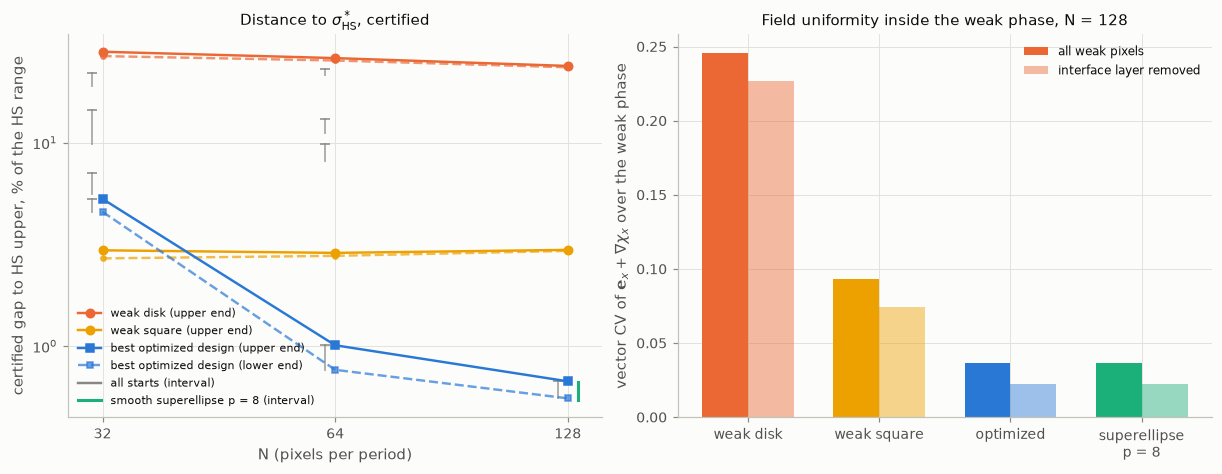

In [14]:
# --- Figure 2: certified gap against N; Figure 3: designs and interior fields
fig, ax = plt.subplots(1, 2, figsize=(11.0, 4.2))
a0 = ax[0]
for n in (32, 64, 128):
    for c in D4[n]:
        a0.plot([n * 0.97] * 2, [max(100 * c["gap"][0], 1e-2), 100 * c["gap"][1]], color=MUTED, lw=1.2, alpha=0.7)
        a0.plot(n * 0.97, 100 * c["gap"][1], "_", color=MUTED, ms=7)
for k, (lbl, col) in enumerate((("weak disk", CAT[1]), ("weak square", CAT[3]))):
    ns = np.array([32, 64, 128])
    a0.plot(ns * (1.0 + 0.0), [100 * CTRL[n][k]["gap"][1] for n in ns], "o-", color=col, label=f"{lbl} (upper end)")
    a0.plot(ns, [max(100 * CTRL[n][k]["gap"][0], 1e-2) for n in ns], "o--", color=col, ms=3.5, alpha=0.7)
bests = [best_of(n)[0] for n in (32, 64, 128)]
a0.plot([32, 64, 128], [100 * b["gap"][1] for b in bests], "s-", color=CAT[0], label="best optimized design (upper end)")
a0.plot([32, 64, 128], [max(100 * b["gap"][0], 1e-2) for b in bests], "s--", color=CAT[0], ms=3.5, alpha=0.7, label="best optimized design (lower end)")
a0.plot([], [], color=MUTED, label="all starts (interval)")
a0.plot([128 * 1.03] * 2, [100 * sup_best["gap"][0], 100 * sup_best["gap"][1]], color=CAT[2], lw=2.0, label=f"smooth superellipse p = {sup_best['p']} (interval)")
a0.set(xscale="log", yscale="log", xlabel="N (pixels per period)", ylabel="certified gap to HS upper, % of the HS range",
       title=r"Distance to $\sigma^*_{\mathrm{HS}}$, certified", xticks=[32, 64, 128], xticklabels=["32", "64", "128"])
a0.minorticks_off()
a0.legend(fontsize=7.5, loc="lower left")
a1 = ax[1]
w_ = 0.35
labs = ["weak disk", "weak square", "optimized", f"superellipse\np = {sup_best['p']}"]
cols4 = [CAT[1], CAT[3], CAT[0], CAT[2]]
a1.bar(np.arange(4) - w_ / 2, [cv_d, cv_s, cv_o, sup_best["cv"]], w_, color=cols4, label="all weak pixels")
a1.bar(np.arange(4) + w_ / 2, [CTRL[128][0]["cv_core"], CTRL[128][1]["cv_core"], b128["cv_core"], sup_best["cv_core"]], w_, color=cols4, alpha=0.45, label="interface layer removed")
a1.set(xticks=range(4), xticklabels=labs, ylabel=r"vector CV of $\mathbf{e}_x+\nabla\chi_x$ over the weak phase", title="Field uniformity inside the weak phase, N = 128")
a1.legend(fontsize=8)
plt.show()

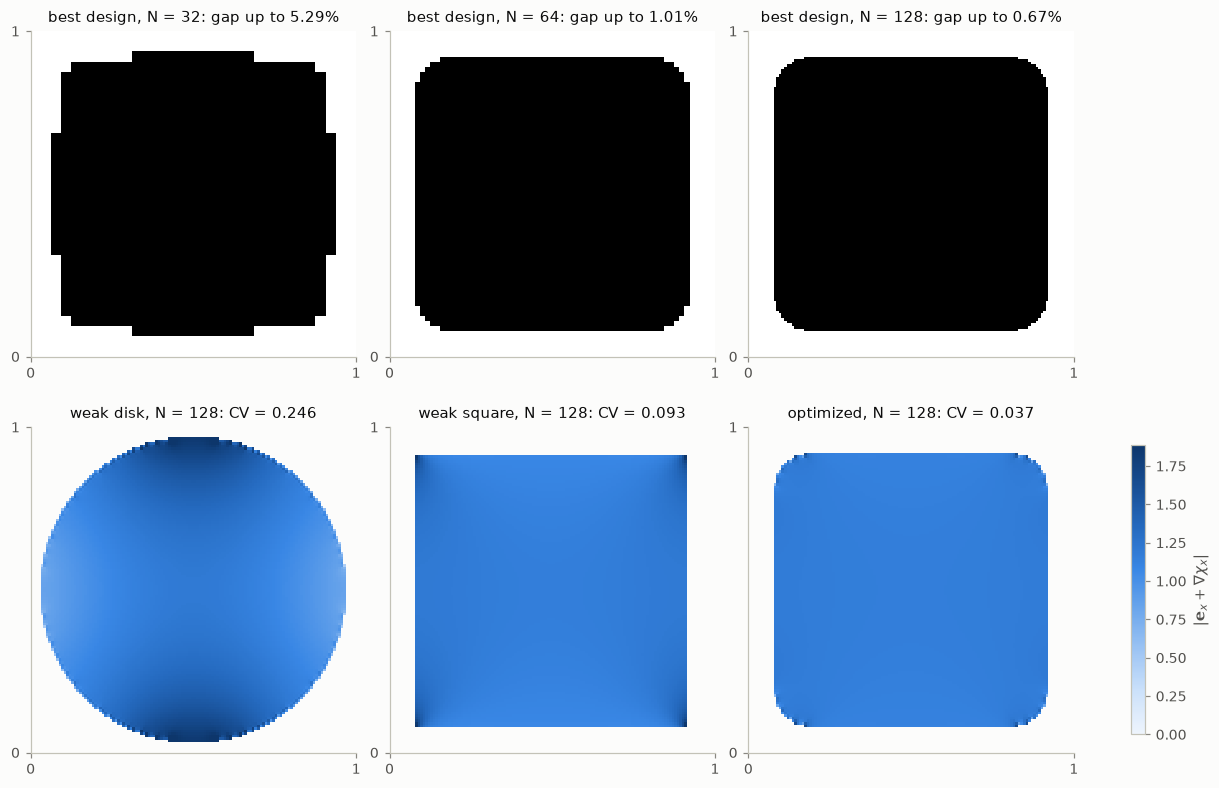

In [15]:
fig, axes = plt.subplots(2, 3, figsize=(11.0, 7.2))
for a, n in zip(axes[0], (32, 64, 128)):
    b = best_of(n)[0]
    a.imshow((~b["strong"]).T, cmap="gray_r", extent=(0, 1, 0, 1))
    a.set(title=f"best design, N = {n}: gap up to {100*b['gap'][1]:.2f}%", xticks=[0, 1], yticks=[0, 1])
    a.grid(False)
vmax = 0.0
fields = []
for c in (CTRL[128][0], CTRL[128][1], b128):
    U_, chi_ = cs.q1_effective(sigma_of(c["strong"]), True)
    F = cs.q1_center_field(chi_, 0)
    fields.append(np.hypot(F[0], F[1]))
lo_, hi_ = 0.0, max(np.percentile(f_[~c["strong"]], 99.5) for f_, c in zip(fields, (CTRL[128][0], CTRL[128][1], b128)))
for a, f_, c, nm in zip(axes[1], fields, (CTRL[128][0], CTRL[128][1], b128), ("weak disk", "weak square", "optimized")):
    im = a.imshow(np.where(c["strong"], np.nan, f_).T, cmap="seq_blue", vmin=lo_, vmax=hi_, extent=(0, 1, 0, 1))
    a.set(title=f"{nm}, N = 128: CV = {c['cv']:.3f}", xticks=[0, 1], yticks=[0, 1])
    a.grid(False)
fig.colorbar(im, ax=axes[1], shrink=0.8, label=r"$|\mathbf{e}_x+\nabla\chi_x|$")
plt.show()

## 5. An anisotropic boundary point

The target is the point of the upper trace curve at $m^*=0.25$, $\lambda=(3.24397,\,2.10031)$, and the objective is $J=U_{xx}+wU_{yy}$ with the weight $w=0.7314$ computed in section 1 (not 0.68). A rank-two laminate (two scales) attains the maximum $J_{\max}$ exactly. P1 says a single anisotropic periodic inclusion attains it too; P2 (relaxation) says designs develop ever finer stripes. Each finer design is warm-started from the upsampled coarser one; the fraction of pixels that differ between the binary design at $N$ and the $2\times2$ upsampled design at $N/2$ then measures how far a warm-started optimizer moves from its start. By construction that is small, so it is reported but it is not a test of P2. A test of whether the optimum is a stable basin is the perturbation test below: perturb the design, re-optimize from $\beta=2$, and see whether the optimizer returns to the same rounded rectangle.

**Method.** D2 symmetry (mirrors in $x$ and $y$; the C4 symmetry of section 4 is dropped), the same pipeline with $J=U_{xx}+wU_{yy}$ and the weak fraction 0.7. The exact maximum is recomputed at the actual fraction of each design. The gap is $(J_{\max}(\theta_{\rm pix})-J)/(J_{\max}-J_{\min})$, with the range 1.9291 taken at $\theta=0.7$ from section 1 (the minimum refined on the lower trace curve); its upper end uses $J_l=L_{xx}+wL_{yy}$ and its lower end $J_u=U_{xx}+wU_{yy}$ (valid because $\operatorname{Tr}(\mathrm{diag}(1,w)\,\cdot)$ is monotone in the Loewner order). The gap is thus a share of the whole range of the objective, on which trivial designs already do well: the controls below give the scale. Starts at $N=32$: seeds 0 and 1, a stripe laminate with layer normal $y$ and the best weak rectangle of a scan. The scan is a one-parameter family of single-scale anisotropic inclusions (even sides, fraction within 0.0075 of 0.7), scored by the certified lower bound of $J$ at that $N$. The rectangle start is included because in trial runs the seeded and stripe starts stopped in laminate-like local optima that are worse than a hand-made rectangle (see the table); the scan makes the rectangle start reproducible. Then: the $N=64$ design is warm-started from the best $N=32$ design, independent starts at $N=64$ are the stripe and seed 0, and $N=128$ is warm-started from the best $N=64$ design. Controls at each $N$: the rank-1 laminate (normal $y$; this is not the two-scale benchmark, which would be a rank-2 laminate, see the caveats) and the raw weak rectangle that the best chain starts from (the $2\times2$ upsampling of the $N=64$ one at $N=128$), certified without optimization. Perturbation tests of the best design: at $N=128$, a random flip of 2% of the pixels (with their D2 images), and at $N=64$ erosion and dilation of the strong phase by one pixel (about 5% of the pixels, shifting the weak fraction to 0.7510 and 0.6504); each is re-optimized with $\beta=2,4,8,16,32$ (30 iterations each at $N=128$, 40 at $N=64$). The final cells also record where the best design sits on the upper trace curve, since the objective is flat there.

In [16]:
# --- section 5: an anisotropic boundary point, D2 designs
T_D2 = time.perf_counter()

def rect_start(N, wx, wy):
    """Weak rectangle wx x wy pixels (even sides, centered) in a strong matrix, as a density (1 = strong)."""
    st = np.ones((N, N))
    x0, y0 = (N - wx) // 2, (N - wy) // 2
    st[x0:x0 + wx, y0:y0 + wy] = 0.0
    return st


def objective(c):
    """Certified interval [J_l, J_u] of U_xx + w U_yy (from the 2N bracket) and the exact maximum at the design's fraction."""
    L, U = c["L"], c["U"]
    return L[0, 0] + W_OBJ * L[1, 1], U[0, 0] + W_OBJ * U[1, 1], jmax_exact(c["th"])[0]


def gap_obj(c):
    """Certified interval of (J_max(theta) - J)/range, range = J_max - J_min of the G-closure at theta = 0.7."""
    Jl, Ju, Jm = objective(c)
    return max(0.0, (Jm - Ju) / J_RANGE), (Jm - Jl) / J_RANGE


def best_rectangle(N):
    """Scan weak rectangles (even sides, fraction within 0.0075 of 0.7) at resolution N; return the one with the smallest certified gap."""
    best = None
    for wx in range(int(0.6 * N) // 2 * 2, N - 1, 2):
        for wy in range(int(0.5 * N) // 2 * 2, N - 1, 2):
            if abs(wx * wy / N ** 2 - THETA) > 0.0075:
                continue
            L, U = cs.q1_bracket(sigma_of(rect_start(N, wx, wy) == 1.0))
            gap = jmax_exact(wx * wy / N ** 2)[0] - (L[0, 0] + W_OBJ * L[1, 1])
            if best is None or gap < best[0]:
                best = (gap, wx, wy)
    return best

D2 = {32: [], 64: [], 128: []}
def run_d2(N, kind, rho0, betas, iters):
    t = time.perf_counter()
    rho, Jg = optimize(rho0, N, "D2", W_OBJ, betas, iters)
    c = certify(binarize(rho, N, "D2"))
    c.update(N=N, kind=kind, Jgray=Jg, secs=time.perf_counter() - t, parent=None, root=kind)
    c["gap"] = gap_obj(c)
    D2[N].append(c)
    return c

def stripe_start(N):
    return cs.laminate_pixels(N, int(round((1 - THETA) * N)), 1.0, 0.0, axis=1)           # strong band, layer normal y

RECT = {}
for N in (32, 64):
    RECT[N] = best_rectangle(N)
    print(f"N = {N}: best weak rectangle {RECT[N][1]} x {RECT[N][2]} pixels (aspect {RECT[N][1] / RECT[N][2]:.2f}), certified shortfall of the objective {RECT[N][0]:.4f}")

def warm(N, parent):
    c = run_d2(N, f"{parent['root']}, warm", up2(parent["strong"]).astype(float), BETAS_WARM, 40)
    c["parent"], c["ham"], c["root"] = parent, np.mean(c["strong"] != up2(parent["strong"])), parent["root"]
    return c

for kind, rho0 in (("rectangle", rect_start(32, *RECT[32][1:])), ("stripe", stripe_start(32)), (0, start_density(32, 0)), (1, start_density(32, 1))):
    run_d2(32, kind, rho0, BETAS, 40)
best32 = sorted(D2[32], key=lambda c: c["gap"][1])[0]
warm(64, best32)
same_rect = (RECT[64][1], RECT[64][2]) == (2 * RECT[32][1], 2 * RECT[32][2])
print(f"best rectangle at N = 64 is {'the 2x2 upsampling of the N = 32 one' if same_rect else 'a different shape'}")
for kind, rho0 in ((("rectangle", rect_start(64, *RECT[64][1:])),) if not same_rect else ()) + (("stripe", stripe_start(64)), (0, start_density(64, 0))):
    run_d2(64, kind, rho0, BETAS, 40)
best64 = sorted(D2[64], key=lambda c: c["gap"][1])[0]
warm(128, best64)
print(f"D2 designs: {time.perf_counter() - T_D2:.1f} s")

# controls: the rank-1 laminate (normal y; a rank-1 laminate is not the two-scale benchmark, which is a rank-2 laminate) and the raw weak rectangle that the
# optimizer started from (at N = 128 the 2x2 upsampling of the N = 64 one)
lam_ctrl, RAWRECT = {}, {}
for N in (32, 64, 128):
    a = cs.laminate_pixels(N, int(round((1 - THETA) * N)), S2, S1, axis=1)
    c = certify(a == S2)
    c.update(N=N, kind="rank-1 laminate, normal y")
    c["gap"] = gap_obj(c)
    lam_ctrl[N] = c
    wx_, wy_ = (RECT[N][1], RECT[N][2]) if N in RECT else (2 * RECT[64][1], 2 * RECT[64][2])
    c = certify(rect_start(N, wx_, wy_) == 1.0)
    c.update(N=N, kind=f"raw rectangle {wx_} x {wy_}")
    c["gap"] = gap_obj(c)
    RAWRECT[N] = c

# perturbation tests of the anisotropic optimum: does re-optimization return to the same design?
def flip_random(strong, frac, seed):
    """Flip each pixel of one quadrant with probability frac, together with its D2 mirror images (so the perturbation keeps the symmetry)."""
    N = strong.shape[0]
    q = np.random.default_rng(seed).random((N // 2, N // 2)) < frac
    m = np.zeros((N, N), bool)
    m[:N // 2, :N // 2] = q
    m = m | m[::-1, :] | m[:, ::-1] | m[::-1, ::-1]
    return np.where(m, ~strong, strong)


def dilate_strong(strong):
    """Strong phase grown by one pixel (4-neighborhood, periodic)."""
    out = strong.copy()
    for ax in (0, 1):
        out = out | np.roll(strong, 1, ax) | np.roll(strong, -1, ax)
    return out


def erode_strong(strong):
    return ~dilate_strong(~strong)


PERT = []
def run_pert(N, name, start, orig, iters):
    t = time.perf_counter()
    rho, Jg = optimize(start.astype(float), N, "D2", W_OBJ, (2, 4, 8, 16, 32), iters)
    c = certify(binarize(rho, N, "D2"))
    c.update(N=N, kind=name, orig=orig, ham_start=np.mean(start != orig["strong"]), ham_orig=np.mean(c["strong"] != orig["strong"]),
             frac_start=1 - start.mean(), secs=time.perf_counter() - t)
    c["gap"] = gap_obj(c)
    PERT.append(c)

bd2_pre = {N: sorted(D2[N], key=lambda c: c["gap"][1])[0] for N in D2}
run_pert(128, "2% random flip", flip_random(bd2_pre[128]["strong"], 0.02, 5), bd2_pre[128], 30)
run_pert(64, "erode strong by 1 px", erode_strong(bd2_pre[64]["strong"]), bd2_pre[64], 40)
run_pert(64, "dilate strong by 1 px", dilate_strong(bd2_pre[64]["strong"]), bd2_pre[64], 40)
print(f"perturbation tests done, {time.perf_counter() - T_D2:.1f} s in total for this section")

N = 32: best weak rectangle 30 x 24 pixels (aspect 1.25), certified shortfall of the objective 0.0313
N = 64: best weak rectangle 60 x 48 pixels (aspect 1.25), certified shortfall of the objective 0.0283


best rectangle at N = 64 is the 2x2 upsampling of the N = 32 one


D2 designs: 31.2 s


perturbation tests done, 59.3 s in total for this section


In [17]:
print(f"objective U_xx + w U_yy, w = {W_OBJ:.4f}; exact maximum over the G-closure at the design's own fraction; range of the objective {J_RANGE:.4f}")
print(f"{'N':>4s} {'start':>28s} {'frac':>7s} {'J_max':>8s} {'J lower':>8s} {'J upper':>8s} {'(L_xx, L_yy)':>16s} {'gap lower':>10s} {'gap upper':>10s}")
for N in (32, 64, 128):
    for c in D2[N] + [RAWRECT[N], lam_ctrl[N]]:
        Jl, Ju, Jm = objective(c)
        print(f"{N:4d} {str(c['kind']):>28s} {c['th']:7.4f} {Jm:8.4f} {Jl:8.4f} {Ju:8.4f}  ({c['L'][0,0]:6.3f},{c['L'][1,1]:6.3f}) {100*c['gap'][0]:9.2f}% {100*c['gap'][1]:9.2f}%")

objective U_xx + w U_yy, w = 0.7314; exact maximum over the G-closure at the design's own fraction; range of the objective 1.9291
   N                        start    frac    J_max  J lower  J upper     (L_xx, L_yy)  gap lower  gap upper
  32                    rectangle  0.6992   4.7891   4.7654   4.7714  ( 3.334, 1.957)      0.92%      1.22%
  32                       stripe  0.6992   4.7891   4.6305   4.6415  ( 3.620, 1.381)      7.65%      8.22%
  32                            0  0.6992   4.7891   4.5482   4.6075  ( 2.977, 2.148)      9.41%     12.49%
  32                            1  0.6992   4.7891   4.5749   4.6338  ( 2.866, 2.336)      8.05%     11.10%
  32        raw rectangle 30 x 24  0.7031   4.7446   4.7163   4.7197  ( 3.307, 1.927)      1.29%      1.47%
  32    rank-1 laminate, normal y  0.6875   4.9234   4.8301   4.8301  ( 3.813, 1.391)      4.84%      4.84%
  64              rectangle, warm  0.7002   4.7779   4.7597   4.7623  ( 3.331, 1.953)      0.81%      0.95%
  64  

In [18]:
allD = [c for N in D2 for c in D2[N]] + list(lam_ctrl.values()) + list(RAWRECT.values()) + PERT
min_rig = min(objective(c)[2] - objective(c)[0] for c in allD)
print(f"{len(allD)} certified designs, controls and re-optimized designs: smallest J_max(theta) - J_lower = {min_rig:.4f}")
check_in("rigor: certified J_lower = L_xx + w L_yy <= exact maximum at the design's fraction (min slack, all designs)", min_rig, -1e-12, np.inf)
# The rank-1 laminate sits exactly on the Wiener boundary, so for it the sign of the certification is decided by the rounding of the 2N = 256 solve.
n_viol_opt = sum(bd.certified_violation(c["L"], c["U"], S1, S2, c["th"]) for c in [c for N in D2 for c in D2[N]] + list(RAWRECT.values()) + PERT)
n_viol_lam = sum(bd.certified_violation(c["L"], c["U"], S1, S2, c["th"], tol=1e-9) for c in lam_ctrl.values())
n_viol_lam_strict = sum(bd.certified_violation(c["L"], c["U"], S1, S2, c["th"]) for c in lam_ctrl.values())
print(f"certified violations: {n_viol_opt} of {len([c for N in D2 for c in D2[N]] + list(RAWRECT.values()) + PERT)} D2 designs, raw rectangles and re-optimized designs (tolerance 1e-12); "
      f"rank-1 laminate controls {n_viol_lam} of 3 at tolerance 1e-9, {n_viol_lam_strict} of 3 at 1e-12 (rounding of the exact Wiener-boundary tensor)")
check_in("no D2 design, raw rectangle or re-optimized design is certified to violate the G-closure (count, tolerance 1e-12)", float(n_viol_opt), 0.0, 0.0)
check_in("no rank-1 laminate control is certified to violate the G-closure (count, tolerance 1e-9: the laminate lies on the Wiener boundary)", float(n_viol_lam), 0.0, 0.0)
check_in("unit test: D2 designs are diagonal: |U_xy| (max over designs, at 2N)", max(abs(c["U"][0, 1]) for c in allD), 0.0, 1e-10)
check_in("construction: weak fraction of every D2 design within 8/N^2 of 0.7 (max of |theta - 0.7| N^2 / 8)", max(abs(c["th"] - THETA) * c["N"] ** 2 / 8 for N in D2 for c in D2[N]), 0.0, 1.0)

bd2 = {N: sorted(D2[N], key=lambda c: c["gap"][1])[0] for N in D2}
print("best certified D2 design at each N:", ", ".join(f"N = {n}: gap [{100*b['gap'][0]:.2f}%, {100*b['gap'][1]:.2f}%] ({b['kind']})" for n, b in bd2.items()))
print("raw weak rectangle (the start of the best chain):", ", ".join(f"N = {n}: gap [{100*RAWRECT[n]['gap'][0]:.2f}%, {100*RAWRECT[n]['gap'][1]:.2f}%]" for n in RAWRECT))
print("rank-1 laminate control:", ", ".join(f"N = {n}: gap [{100*lam_ctrl[n]['gap'][0]:.2f}%, {100*lam_ctrl[n]['gap'][1]:.2f}%]" for n in lam_ctrl))
chain = [bd2[32]] + [[c for c in D2[N] if c["parent"] is not None][0] for N in (64, 128)]
for N in (64, 128):
    ch = chain[1 if N == 64 else 2]
    print(f"N = {N} warm-started design: Hamming change from its upsampled N = {N // 2} parent {100*ch['ham']:.2f}% of the pixels; objective of the parent at N = {N//2}: gap upper end {100*ch['parent']['gap'][1]:.2f}%, child {100*ch['gap'][1]:.2f}%")
# descriptive: both are properties of the warm-started chain; the Hamming change measures how little the optimizer moves from its start, it is not a test of P2
check_in("descriptive: D2 warm chain, the upper end of the gap decreases with N (smaller of the two differences 32 -> 64, 64 -> 128)",
         min(chain[0]["gap"][1] - chain[1]["gap"][1], chain[1]["gap"][1] - chain[2]["gap"][1]), 0.0, np.inf)
check_in("descriptive (displacement of a warm-started optimizer, not a test of P2): Hamming change from the upsampled parent (max over the two refinements)",
         max(chain[1]["ham"], chain[2]["ham"]), 0.0, 0.005)

print("perturbation tests (D2 designs re-optimized with beta = 2, 4, 8, 16, 32):")
for c in PERT:
    print(f"  N = {c['N']}, {c['kind']}: perturbed start differs from the design in {100*c['ham_start']:.2f}% of the pixels (weak fraction {c['frac_start']:.4f} against {c['orig']['th']:.4f}); "
          f"re-optimized gap [{100*c['gap'][0]:.2f}%, {100*c['gap'][1]:.2f}%] against the design's [{100*c['orig']['gap'][0]:.2f}%, {100*c['orig']['gap'][1]:.2f}%]; "
          f"Hamming distance of the result to the design {100*c['ham_orig']:.2f}% ({c['secs']:.1f} s)")
c_flip = [c for c in PERT if c["kind"] == "2% random flip"][0]
check_in("descriptive: N = 128, after a 2% random flip, re-optimization returns to within 0.5% of the pixels of the design (Hamming distance; value set after the run)", c_flip["ham_orig"], 0.0, 0.005)

# where on the upper trace curve does the best design sit?  The slack of the upper trace inequality is decreasing in the eigenvalues, so the true slack
# lies between its value at eig(U) (the smallest, the pessimistic end: this is the certification) and at eig(L) (the largest, the optimistic end).
mm_fine = np.linspace(0, 1, 200001)
curve_fine = rank2_strong(THETA, mm_fine)
print("best D2 design at each N: certified position relative to the upper trace curve (fraction theta of the design; curve at theta = 0.7)")
print(f"{'N':>4s} {'upper trace slack, true value in':>34s} {'m of the curve point with the same lambda_x':>45s} {'lambda_y on the curve':>22s} {'design lambda_y in':>20s} {'J along the curve there':>24s}")
POS = {}
for N in (32, 64, 128):
    c = bd2[N]
    eL, eU = np.diag(c["L"]), np.diag(c["U"])
    s_pess = bd.trace_slacks(eU[0], eU[1], S1, S2, c["th"])[1]      # at eig(U): smallest slack, the certification
    s_opt = bd.trace_slacks(eL[0], eL[1], S1, S2, c["th"])[1]       # at eig(L): largest slack
    k = int(np.argmin(np.abs(curve_fine[:, 0] - 0.5 * (eL[0] + eU[0]))))
    Jc = curve_fine[k, 0] + W_OBJ * curve_fine[k, 1]
    POS[N] = dict(slack=(s_pess, s_opt), m=mm_fine[k], Jc=Jc, ly=curve_fine[k, 1])
    print(f"{N:4d} {'[' + format(s_pess, '.2e') + ', ' + format(s_opt, '.2e') + ']':>34s} {mm_fine[k]:45.4f} {curve_fine[k, 1]:22.4f} {'[' + format(eL[1], '.4f') + ', ' + format(eU[1], '.4f') + ']':>20s} {Jc:24.4f}")
    check_in(f"N = {N}: upper-trace slack at the pessimistic end eig(U) is positive (certified inside the G-closure; a priori criterion)", s_pess, 0.0, np.inf)
Jl128, Ju128, Jm128 = objective(bd2[128])
print(f"exact maximum of the objective {J_STAR:.4f} at m = 0.25; the curve value at the design's m is lower by {J_STAR - POS[128]['Jc']:.4f} ({100*(J_STAR - POS[128]['Jc'])/J_RANGE:.2f}% of the objective range), "
      f"the design's certified lower bound J_lower by a further {POS[128]['Jc'] - Jl128:.4f} ({100*(POS[128]['Jc'] - Jl128)/J_RANGE:.2f}% of the range) (N = 128)")
eL128, eU128 = np.diag(bd2[128]["L"]), np.diag(bd2[128]["U"])
print(f"N = 128: at the design's lambda_x the curve has lambda_y = {POS[128]['ly']:.4f}, the design has lambda_y in [{eL128[1]:.4f}, {eU128[1]:.4f}], i.e. {100*(POS[128]['ly'] - eU128[1])/POS[128]['ly']:.2f}% to {100*(POS[128]['ly'] - eL128[1])/POS[128]['ly']:.2f}% below the curve; "
      f"the design's curve point has m = {POS[128]['m']:.4f}, |m - 0.25| = {abs(POS[128]['m'] - 0.25):.4f} (a printed finding, not a check)")
print(f"best N = 128 design: J in [{Jl128:.4f}, {Ju128:.4f}], maximum {Jm128:.4f}: shortfall at most {100*(Jm128 - Jl128)/Jm128:.2f}% of J_max, {100*(Jm128 - Jl128)/J_RANGE:.2f}% of the objective range; "
      f"the rank-1 laminate control is {100*(objective(lam_ctrl[128])[2] - objective(lam_ctrl[128])[0])/objective(lam_ctrl[128])[2]:.2f}% below its own maximum")
spread = {N: sorted(100 * c["gap"][1] for c in D2[N]) for N in D2}
print("upper ends of the gap over all starts:", "; ".join(f"N = {n}: " + ", ".join(f"{g:.1f}%" for g in spread[n]) for n in spread))

17 certified designs, controls and re-optimized designs: smallest J_max(theta) - J_lower = 0.0145
PASS  rigor: certified J_lower = L_xx + w L_yy <= exact maximum at the design's fraction (min slack, all designs): got 0.0144941, required in [-1e-12, inf]
certified violations: 0 of 14 D2 designs, raw rectangles and re-optimized designs (tolerance 1e-12); rank-1 laminate controls 0 of 3 at tolerance 1e-9, 1 of 3 at 1e-12 (rounding of the exact Wiener-boundary tensor)
PASS  no D2 design, raw rectangle or re-optimized design is certified to violate the G-closure (count, tolerance 1e-12): got 0, required in [0, 0]
PASS  no rank-1 laminate control is certified to violate the G-closure (count, tolerance 1e-9: the laminate lies on the Wiener boundary): got 0, required in [0, 0]
PASS  unit test: D2 designs are diagonal: |U_xy| (max over designs, at 2N): got 2.65975e-16, required in [0, 1e-10]
PASS  construction: weak fraction of every D2 design within 8/N^2 of 0.7 (max of |theta - 0.7| N^2 / 8):

**Reading the table.** Gradient designs from generic starts stop far from the target: the stripe start keeps its laminate (gap upper end 8.22% at $N=32$ and 5.19% at $N=64$; the rank-1 laminate control is at 4.84% and 3.87%) and the seeded starts end at 11% to 20%. A weak rectangle of aspect 1.25 ($30\times24$ pixels at $N=32$, the scan's choice, and its $2\times2$ upsampling is the scan's choice at $N=64$) is already close (the raw rectangle is at 1.47%, 1.41%, 1.39% at $N=32,64,128$), and the optimizer converges from it to a rounded rectangle with certified gap intervals $[0.92\%,1.22\%]$, $[0.81\%,0.95\%]$ and $[0.69\%,0.75\%]$ at $N=32,64,128$. This is a single-scale design within 0.75% of the objective range of the exact maximum, which a rank-two laminate attains. The scale matters: the range 1.9291 includes trivial designs that already score well, so 0.75% is a factor of about 1.9 below the raw rectangle (1.39%) and about 5.2 below the rank-1 laminate (3.87%), not orders of magnitude. The statement is limited to the chain: the starts that are not a rectangle do not find it, so the evidence concerns one basin, found with the help of a scan, and says nothing about whether another structure is better.

The Hamming changes under refinement, 0.10% and 0.12% of the pixels, measure how little a warm-started optimizer moves in 160 iterations from $\beta=4$; they do not show that the design "does not develop finer stripes" and are not a test of P2, whose competitor (the rank-2 laminate) was not computed at all. The perturbation test is the relevant one. At $N=128$ a random flip of 2% of the pixels (the start differs from the design in 2.15% of the pixels, at weak fraction 0.6941) is re-optimized to a design that differs from the original in 0.05% of the pixels, with the same gap $[0.69\%,0.75\%]$: the optimum is stable against random noise of that size. But at $N=64$ one-pixel erosion or dilation of the strong phase (a global displacement of the interface, 5% of the pixels) is not undone: the re-optimized designs have gap intervals $[11.34\%,12.06\%]$ and $[15.05\%,18.37\%]$ against $[0.81\%,0.95\%]$, at Hamming distance 6.25% and 5.27% from the design. So the rounded rectangle is a local optimum of the pipeline with a basin that is narrow against interface shifts, consistent with the failure of the other starts to find it.

The second printout locates the design. Its tensor is certified to lie inside the G-closure at every $N$: the slack of the upper trace inequality at $\lambda(U)$, the smallest value in the bracket, is positive ($3.2\times10^{-4}$, $2.8\times10^{-4}$, $2.2\times10^{-4}$ at $N=32,64,128$) and the true slack lies between it and the value at $\lambda(L)$ ($4.5\times10^{-4}$, $3.3\times10^{-4}$, $2.5\times10^{-4}$). The curve point with the same $\lambda_x$ has $m\approx0.20$ ($0.2024$ at $N=128$, so $|m-0.25|=0.0476$), not 0.25. The shortfall has two parts: the position along the curve (the objective is stationary at $m^*$, so this part is second order) and the distance from the curve (first order). At $N=128$ the curve value at the design's $m$ is 0.0028 below the maximum (0.14% of the objective range; the curve is taken at $\theta_1=0.7$, while the design's fraction is 0.69995, which moves $J_{\max}$ by 0.0005), and the certified $J_l$ is a further 0.0111 below (0.58% of the range): the second part is the larger. The slack of $2\times10^{-4}$ is in units of 1/conductivity and looks smaller than the geometric distance: at the design's $\lambda_x$ the curve has $\lambda_y=1.9709$ and the design $\lambda_y\in[1.9562,1.9569]$, that is 0.71% to 0.75% below the curve. The design reaches the neighborhood of the boundary, but at $m\approx0.20$ and not at the target point, and its closeness in $J$ comes from the flatness of $J$ along the curve: $J$ cannot tell $m=0.20$ from $m=0.25$ at this level (the curve value is 4.7774 at the design's $m$ and 4.7802 at $m^*$).

Figure 4: certified tensors of the D2 designs (boxes from $L$ to $U$ at $2N$; the inset magnifies the best design at each $N$) against the upper trace curve and the supporting line of the objective (left), and the certified gap against $N$ (right; all starts in gray). Figure 5: the best design at $N=32,64,128$ (weak phase black) and a seeded start at $N=64$ that stopped in a local optimum.

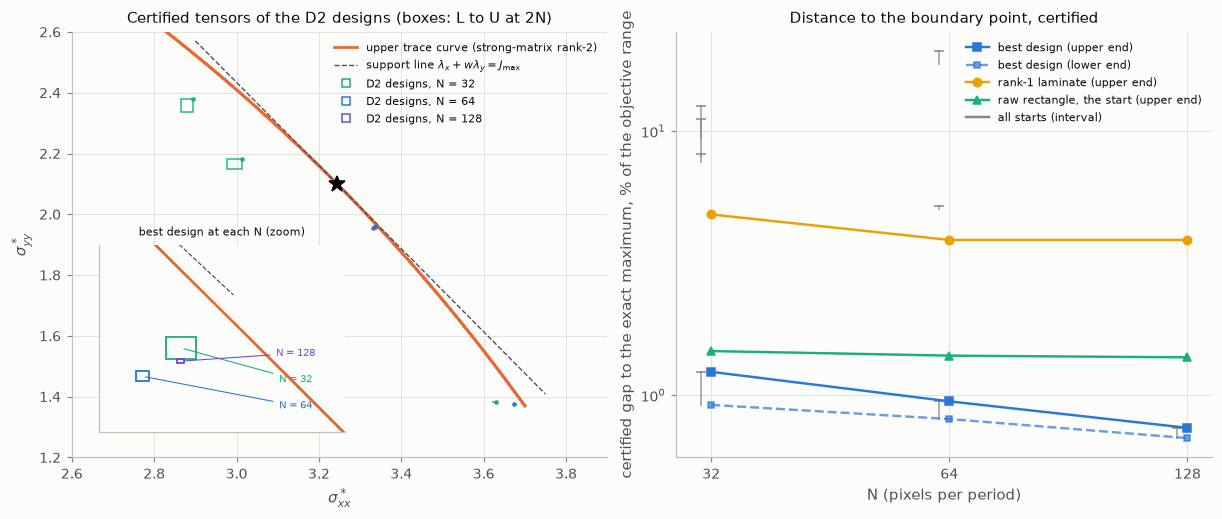

In [19]:
# --- Figure 4: the certified points near the target; Figure 5: designs
fig, ax = plt.subplots(1, 2, figsize=(11.0, 4.6))
a0 = ax[0]
lamc = np.sort(rank2_strong(THETA, np.linspace(0, 1, 801)), axis=1)[:, ::-1]
a0.plot(*lamc.T, color=CAT[1], lw=1.8, label="upper trace curve (strong-matrix rank-2)")
xs = np.linspace(2.9, 3.75, 50)
a0.plot(xs, (J_STAR - xs) / W_OBJ, color=INK2, lw=0.9, ls="--", label=r"support line $\lambda_x+w\lambda_y=J_{\max}$")
a0.plot(*lam_star, "k*", ms=11)
cols = {32: CAT[2], 64: CAT[0], 128: CAT[6]}
for N in (32, 64, 128):
    for c in D2[N]:
        a0.add_patch(plt.Rectangle((c["L"][0, 0], c["L"][1, 1]), c["U"][0, 0] - c["L"][0, 0], c["U"][1, 1] - c["L"][1, 1], fill=False, ec=cols[N], lw=1.0, alpha=0.9))
        a0.plot(c["U"][0, 0], c["U"][1, 1], ".", color=cols[N], ms=4)
    a0.plot([], [], "s", mfc="none", color=cols[N], label=f"D2 designs, N = {N}")
a0.set(xlabel=r"$\sigma^*_{xx}$", ylabel=r"$\sigma^*_{yy}$", xlim=(2.6, 3.9), ylim=(1.2, 2.6), title="Certified tensors of the D2 designs (boxes: L to U at 2N)")
a0.legend(fontsize=7.5, loc="upper right")
# inset: the best design at each N (their boxes are a few thousandths wide), against the upper trace curve and the support line
ins = a0.inset_axes([0.05, 0.06, 0.46, 0.44])
x0_, x1_ = min(bd2[n]["L"][0, 0] for n in bd2) - 0.004, max(bd2[n]["U"][0, 0] for n in bd2) + 0.004
y0_, y1_ = min(bd2[n]["L"][1, 1] for n in bd2) - 0.004, POS[128]["ly"] + 0.004
xi = np.linspace(x0_, x1_, 20)
ins.plot(xi, (J_STAR - xi) / W_OBJ, color=INK2, lw=0.8, ls="--")
ins.plot(*lamc.T, color=CAT[1], lw=1.5)
for n in (32, 64, 128):
    c = bd2[n]
    ins.add_patch(plt.Rectangle((c["L"][0, 0], c["L"][1, 1]), c["U"][0, 0] - c["L"][0, 0], c["U"][1, 1] - c["L"][1, 1], fill=False, ec=cols[n], lw=1.2))
    ins.annotate(f"N = {n}", xy=(0.5 * (c["L"][0, 0] + c["U"][0, 0]), 0.5 * (c["L"][1, 1] + c["U"][1, 1])), xytext=(0.80, {32: 0.28, 64: 0.14, 128: 0.42}[n]),
                 textcoords="axes fraction", fontsize=6.5, color=cols[n], ha="center", va="center", arrowprops=dict(arrowstyle="-", color=cols[n], lw=0.7))
ins.set(xlim=(x0_, x1_ + 0.012), ylim=(y0_ - 0.004, y1_), title="best design at each N (zoom)", xticks=[], yticks=[])
ins.title.set_fontsize(7)
ins.grid(False)
a1 = ax[1]
for N in (32, 64, 128):
    for c in D2[N]:
        a1.plot([N * 0.97] * 2, [max(100 * c["gap"][0], 1e-2), 100 * c["gap"][1]], color=MUTED, lw=1.2, alpha=0.7)
        a1.plot(N * 0.97, 100 * c["gap"][1], "_", color=MUTED, ms=7)
ns = [32, 64, 128]
a1.plot(ns, [100 * bd2[n]["gap"][1] for n in ns], "s-", color=CAT[0], label="best design (upper end)")
a1.plot(ns, [max(100 * bd2[n]["gap"][0], 1e-2) for n in ns], "s--", color=CAT[0], ms=3.5, alpha=0.7, label="best design (lower end)")
a1.plot(ns, [100 * lam_ctrl[n]["gap"][1] for n in ns], "o-", color=CAT[3], label="rank-1 laminate (upper end)")
a1.plot(ns, [100 * RAWRECT[n]["gap"][1] for n in ns], "^-", color=CAT[2], ms=5, label="raw rectangle, the start (upper end)")
a1.plot([], [], color=MUTED, label="all starts (interval)")
a1.set(xscale="log", yscale="log", xlabel="N (pixels per period)", ylabel="certified gap to the exact maximum, % of the objective range",
       title="Distance to the boundary point, certified", xticks=ns, xticklabels=[str(n) for n in ns])
a1.minorticks_off()
a1.legend(fontsize=7.5, loc="best")
plt.show()

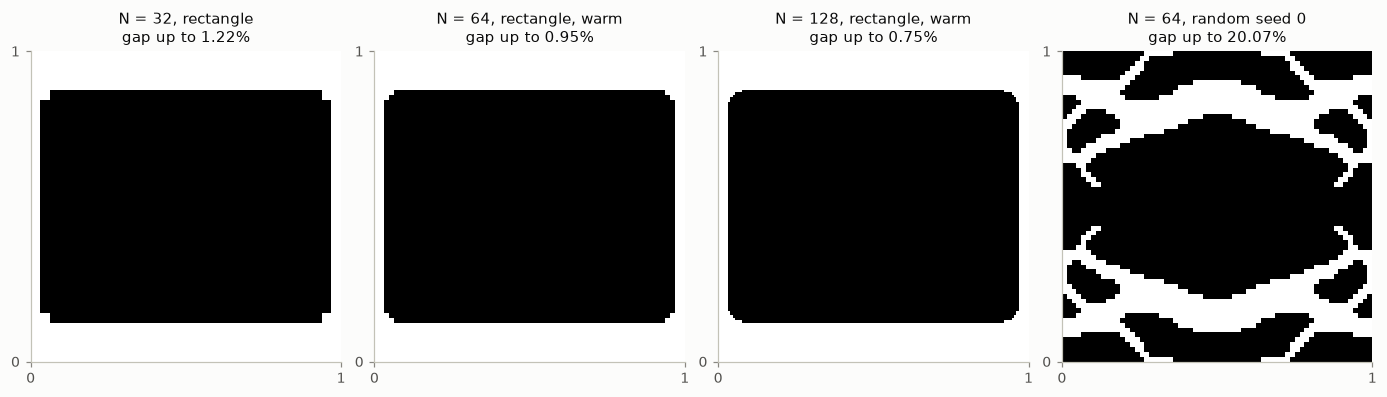

In [20]:
fig, axes = plt.subplots(1, 4, figsize=(12.5, 3.5))
shown = [bd2[32], bd2[64], bd2[128]]
worst64 = sorted(D2[64], key=lambda c: c["gap"][1])[-1]
for a, c in zip(axes, shown + [worst64]):
    a.imshow((~c["strong"]).T, cmap="gray_r", extent=(0, 1, 0, 1))
    a.set(title=f"N = {c['N']}, {'random seed ' + str(c['kind']) if isinstance(c['kind'], int) else c['kind']}\ngap up to {100*c['gap'][1]:.2f}%", xticks=[0, 1], yticks=[0, 1])
    a.grid(False)
plt.show()

## Summary

The two-phase G-closure in 2D is the Wiener box and two trace inequalities, with equality on rank-two laminates; the form in the module is Grabovsky's, no random cell violates it (a weak test), and the objective weight for the anisotropic target is 0.7314, with an objective range of 1.9291. The envelope-theorem gradient is exact, so autodiff design needs no adjoint. With every design certified by the Q1 bracket, gradient designs reach a rounded square with a certified gap of $[0.55\%,0.67\%]$ of the Hashin-Shtrikman range at $N=128$, against 2.97% for the weak square and 23.85% for the weak disk; a smooth superellipse with $p=8$ at the same pixel count is certified at $[0.54\%,0.66\%]$, and its interior field is as uniform (vector CV 0.0363) as the optimized one (0.0366), so the optimizer's field uniformity is the discretization floor at $N=128$. For the anisotropic target a rounded rectangle is within 0.75% of the objective range (the raw rectangle is at 1.39% and the rank-1 laminate at 3.87%), certified inside the G-closure but at $m\approx0.20$ on the upper trace curve and not at the target $m^*=0.25$; the warm-started Hamming change of 0.12% does not test whether finer stripes would develop, and the perturbation test shows a basin that tolerates 2% random flips at $N=128$ but not one-pixel interface shifts at $N=64$. What a finite $N$ cannot decide is whether the gap tends to zero; what it does exclude is a single-scale saturation of periodic pixel cells at $N=128$ above 0.67% of the HS range. The designs found depend on the start: the optimizer from generic starts is stuck in laminate-like optima, and at $N=32$ it turned a good square start into a 21.98% design.

In [21]:
TOTAL = time.perf_counter() - T0
print(f"total run time of the notebook (from the imports): {TOTAL:.1f} s")
check_in("run time within the budget of 170 s", TOTAL, 0.0, 170.0)

total run time of the notebook (from the imports): 115.2 s
PASS  run time within the budget of 170 s: got 115.207, required in [0, 170]


## Caveats and open ends

- **What is certified.** Every bracket concerns the pixel medium. A gap of 0.67% at $N=128$ with a positive lower end does not decide P1 against P2: it excludes any single-scale saturation level above 0.67% of the HS range for periodic pixel cells of 128 pixels at weak fraction 0.7002, and says nothing about the limit $g_\infty$. The convergence is pre-asymptotic: the upper end falls by a factor of about 1.5 from $N=64$ to 128, and with only three resolutions (the coarsest of which is affected by the start) no rate is claimed.
- **U is optimized, L is certified.** The optimizer maximizes the primal upper bound $U_{xx}$ and the gaps are certified from the dual lower bound $L_{xx}$; the notebook does not study how much of the failure of the $N=32$ designs this difference explains. Restarting the best $N=64$ design for 160 more iterations leaves it unchanged, so the change of the gap from 1.01% to 0.67% between $N=64$ and the warm-started child at $N=128$ is not unfinished iteration; the child differs in 0.29% of the pixels, which shows that the certified gap is sensitive to boundary-pixel details at that level and is not converged in that sense.
- **Local optima, the role of the start, and the P2 test.** Gradient designs from generic starts end 5% to 23% from the target (sections 4 and 5), and the best designs came from structured starts (weak square for the isotropic case, weak rectangle from a scan for the anisotropic one). The $N=128$ designs are one warm-started chain per case. The warm-started Hamming changes are small by construction and say nothing about P2. The perturbation test is one random flip at $N=128$ and one erosion and one dilation at $N=64$; no independent random seed at $N=128$ was run, and no rank-2 laminate (the two-scale competitor in P2) was compared, so the two-scale side of P2 is untested.
- **Smooth reference.** The superellipse family is a hand-chosen one-parameter family at the pixel count of the optimized design; it shows that rounding matters and that the optimizer's design is not distinguishable from $p=8$ by its certified gap or field statistic at $N=128$, not that either is the Vigdergauz shape. The field statistic includes the staircase, whose floor at $N=128$ is the superellipse value 0.0363.
- **Pixel disks.** The Rayleigh value of the weak-disk array lies outside the certified bracket of the pixel disk at $N=32$ and 64 (the staircase of the center-sampled disk), so the pixel-disk gaps at those $N$ overstate the gap of a true disk array (23.89% of the range at $\theta_1=0.7$). The same staircase error at $\theta_1=0.5$ ($N=64$) is of the order of the headroom, which is why $\theta_1=0.7$ was used.
- **Tolerances and checks fixed after seeing results.** The step $10^{-4}$ of the finite-difference check (the initial $10^{-6}$ is limited by rounding to $1.45\times10^{-6}$ on the smallest entries); the tolerance $10^{-5}$ of the design-chain gradient check (observed $3.7\times10^{-7}$ at $\beta=1$, 8 and 32); the tolerance $10^{-9}$ for the count of certified violations of the laminate controls (the laminate is exactly on the Wiener boundary, and the solve at $2N=256$ has a rounding error of the order $10^{-12}$ that would otherwise decide the sign at $10^{-12}$); the strict orderings of the vector CV at $N=128$ (shown at $N=128$ only; at $N=32$ the order is different); the descriptive D2 checks (the gap decreases along the warm chain; the warm-started Hamming change is at most 0.5%; the Hamming distance after the 2% flip is at most 0.5%), whose bounds were set after the run and which assert what was found, not a prediction; and the bounds of the V-shape check on the step scan. The certification of the anisotropic design (slack at $\lambda(U)$ positive at every $N$) and the grid-scan checks of section 1 are a priori. Checks labeled unit test or construction (bracket nesting, symmetry of the designs, weak fraction within $8/N^2$, diagonal D2 tensors, closed forms against the module) are interface identities that cannot fail unless the code is broken; they are not evidence about the optimization. The random-cell check is a weak test because the cells lie far inside the region.
- **Computations left out.** The $N=128$ runs are 160 iterations, with one start in each of sections 4 and 5; a second $N=128$ chain in section 4, from a seeded $N=64$ design, was left out to make room for the perturbation tests, the superellipse family and the restart test. A pixel-resolved rank-two laminate at $N=128$ was tried in an exploratory run (not reported), as a two-scale design to compare with the single-scale ones; at this resolution the quantization of the layer fractions scatters its gap between 1.5% and 8%, so it was left out.
- **Controls differ in fraction.** The rank-1 laminate controls have fractions 0.6875 to 0.7031 (whole-pixel layers), the raw rectangle 0.7031, the weak square at $N=32,64$ has fraction 0.7119; every gap is measured against the bound at the design's own fraction, but the comparison of gaps between designs of different fraction is only as fair as that normalization.
- **From the literature.** The trace bounds, the laminate formula and the attainment statements (Liu 2010) are quoted from the literature; the notebook checks self-consistency (equality on laminates, equivalence with Grabovsky's form, no violation by random cells), not the theorems. Liu, James and Leo 2007 do not themselves state HS attainment (the attainment statement is in Liu 2010 and in an unpublished companion draft); Vigdergauz 1994 and Grabovsky-Kohn 1995 concern elasticity. The Vigdergauz shape was not computed independently, so "rounded square" is an observation about the optimizer's output.
- **Record of the design.** PLAN.md records the design, the expectations written before the computations, and the corrections made after an independent review.
- **Not done.** An independent smooth-shape (non-pixel) computation of the E-inclusion with `fg_bracket` or a free-boundary solver; a rank-2 laminate comparison for the anisotropic point; three dimensions; the other trace curve and other boundary points; the elasticity analog; any design with the non-C4 fraction constraints relaxed.

## References

- K. A. Lurie, A. V. Cherkaev, Exact estimates of conductivity of composites formed by two isotropically conducting media taken in prescribed proportion, Proc. Roy. Soc. Edinburgh Sect. A 99 (1984), 71-87; and Exact estimates of the conductivity of a binary mixture of isotropic materials, Proc. Roy. Soc. Edinburgh Sect. A 104 (1986), 21-38.
- L. Tartar, Estimations fines des coefficients homogeneises, in: P. Kree (ed.), Ennio De Giorgi Colloquium, Pitman Res. Notes in Math. 125, London, 1985, pp. 168-187 (the Murat-Tartar G-closure result as cited by Grabovsky); F. Murat, L. Tartar, Calcul des variations et homogeneisation, in: Les methodes de l'homogeneisation: theorie et applications en physique, Eyrolles, Paris, 1985, pp. 319-369 (English translation in Topics in the Mathematical Modelling of Composite Materials, Birkhauser, 1997, pp. 139-173).
- Y. Grabovsky, Bounds and extremal microstructures for two-component composites: a unified treatment based on the translation method, Proc. Roy. Soc. Edinburgh Sect. A 123 (1993), 423-432 (the trace bounds in any dimension; the title is from memory).
- Z. Hashin, S. Shtrikman, A variational approach to the theory of the effective magnetic permeability of multiphase materials, J. Appl. Phys. 33 (1962), 3125-3131.
- L. P. Liu, Hashin-Shtrikman bounds and their attainability for multi-phase composites, Proc. R. Soc. A 466 (2010), 3693-3713 (a periodic microstructure attains an HS bound if and only if it is a periodic E-inclusion).
- L. P. Liu, R. D. James, P. H. Leo, Periodic inclusion-matrix microstructures with constant field inclusions, Metall. Mater. Trans. A 38 (2007), 781-787.
- S. B. Vigdergauz, Two-dimensional grained composites of extreme rigidity, J. Appl. Mech. 61 (1994), 390-394 (elasticity); Y. Grabovsky, R. V. Kohn, Microstructures minimizing the energy of a two phase elastic composite in two space dimensions. II: The Vigdergauz microstructure, J. Mech. Phys. Solids 43 (1995), 949-972 (elasticity).
- Lord Rayleigh, On the influence of obstacles arranged in rectangular order upon the properties of a medium, Phil. Mag. (5) 34 (1892), 481-502.
- J. Vondrejc, J. Zeman, I. Marek, Guaranteed upper-lower bounds on homogenized properties by FFT-based Galerkin method, Comput. Methods Appl. Mech. Engrg. 297 (2015), 258-291 (guaranteed bounds from conjugate trial spaces; the Q1 bracket here is the finite-element version of the same idea).
- G. W. Milton, The Theory of Composites, Cambridge University Press, 2002 (laminates and G-closure; chapter and section numbers not checked).
- G. Allaire, Shape Optimization by the Homogenization Method, Applied Mathematical Sciences, Springer, 2002.
- From memory, not checked: G. Francfort, F. Murat, Homogenization and optimal bounds in linear elasticity, Arch. Rational Mech. Anal. 94 (1986), 307-334 (the sequential laminate formula); M. P. Bendsoe, O. Sigmund, Topology Optimization: Theory, Methods and Applications, Springer, 2003 (filtering, projection and continuation); D. P. Kingma, J. Ba, Adam: a method for stochastic optimization, ICLR 2015.
- In this repository: `notebooks/homogenization/PLAN.md` (the design record of this folder), `cellsolver.py`, `bounds.py`, `rayleigh.py`.